# CS145 NanoQuery

**Starter release: October 19, 2026.**

[NanoQuery: requirements and grading](https://cs145.web.app/projects/project2-science.html)

Connect tables to documents and answer analytical questions. At higher tiers, build a tested SQL library and verified answers, then test whether giving an LLM that library improves generated SQL. No model training or fine-tuning is required.

**Using the project page and notebook:** We’ve aimed to keep the project page and notebook consistent. The project page gives the full requirements and grading; the notebook provides compact guidance, function contracts, and starter code.

The supplied helpers support setup and retrieval; you write your dataset-specific queries, mappings, and tests through T87. For T93–T100, extend your work with verified reference answers and the LLM comparison. You may need to adapt the helpers to your implementation.

You’re welcome to adapt the starter code within the project requirements. If something seems inconsistent or buggy, check the project page and ask privately on Ed; include the error and a small reproducible example for bugs. Note important assumptions in your notebook so we can take them into account when reviewing your work.

Your proposed tier is a planning target, not a score cap. We award partial credit within each rubric category; 80 core points plus 4 library points earns 84.

**Bonus:** Staff select the top five Science projects for overall quality and compelling work; each receives 0–5 bonus points.

Run Setup and Configuration first; the supplied helpers need no edits. Then jump to [Phase 0](#scrollTo=phase-0) or [Phase 1](#scrollTo=phase-1).


In [1]:
# @title Install dependen%pip -q install pyspark==4.0.1 sentence-transformers duckdb pandas pyarrow sqlglot==30.22.0 requests
import os, json, time, re, random, platform, requests, duckdb
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup, Tag
from urllib.parse import urljoin
from pathlib import Path

print("Python:", platform.python_version())
print({
    p: metadata.version(p)
    for p in [
        "pyspark",
        "sentence-transformers",
        "transformers",
        "torch",
        "duckdb",
        "sqlglot"
    ]
})
WORK = Path("p2_work")
WORK.mkdir(exist_ok=True)

# Spark 4 requires Java 17 or 21. Configure Java before starting the JVM.
import shutil, subprocess, sys

def ensure_spark_java():
    java_home = os.environ.get("JAVA_HOME")
    java = str(Path(java_home) / "bin" / "java") if java_home else shutil.which("java")
    major = None
    if java:
        try:
            result = subprocess.run([java, "-version"], capture_output=True, text=True, check=True)
            match = re.search(r'version "(\d+)', result.stderr + result.stdout)
            major = int(match.group(1)) if match else None
        except (OSError, subprocess.CalledProcessError):
            pass
    if major not in (17, 21):
        try:
            import google.colab
        except ImportError:
            raise RuntimeError("Spark needs Java 17 or 21. Install one and set JAVA_HOME, then rerun Setup.") from None
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk-headless"], check=True)
        homes = sorted(Path("/usr/lib/jvm").glob("java-17-openjdk-*"))
        if not homes:
            raise RuntimeError("Java 17 installation was not found under /usr/lib/jvm.")
        java = str(homes[0] / "bin" / "java")
    os.environ["JAVA_HOME"] = str(Path(java).resolve().parent.parent)
    subprocess.run([str(Path(os.environ["JAVA_HOME"]) / "bin" / "java"), "-version"], check=True)

#ensure_spark_java()
#os.environ["PYSPARK_PYTHON"] = sys.executable
#from pyspark.sql import SparkSession
#_setup_spark = (SparkSession.builder.master("local[2]").appName("cs145-p2").config("spark.driver.memory", "2g").getOrCreate())
#try:
#    assert _setup_spark.range(1).count() == 1
#    print("PASS: Java and Spark setup")
#finally:
#    _setup_spark.stop()

Python: 3.11.8
{'pyspark': '4.3.0', 'sentence-transformers': '6.3.0', 'transformers': '5.23.0', 'torch': '2.15.0', 'duckdb': '2.0.1', 'sqlglot': '30.22.0'}


## Retrieve Amazon Review Datasets & Load Into DuckDB

In [2]:
DATA = Path("amazon_reviews")
DATA.mkdir(exist_ok=True)

con = duckdb.connect(str(DATA / "fragrance.duckdb"))

BASE = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/"

FILES = {
    "All_Beauty": BASE + "review_categories/All_Beauty.jsonl.gz",
    "meta_All_Beauty": BASE + "meta_categories/meta_All_Beauty.jsonl.gz",
    "meta_Beauty_and_Personal_Care": BASE + "meta_categories/meta_Beauty_and_Personal_Care.jsonl.gz",
    "Beauty_and_Personal_Care": BASE + "review_categories/Beauty_and_Personal_Care.jsonl.gz"
}

for name, url in FILES.items():
    path = DATA / f"{name}.jsonl.gz"

    if path.exists() and path.stat().st_size > 0:
        print("Exists:", path)
        continue

    partial = DATA / f"{name}.jsonl.gz.part"

    with requests.get(url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        with open(partial, "wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    partial.replace(path)
    print("Downloaded:", path)

Downloaded: amazon_reviews/All_Beauty.jsonl.gz
Downloaded: amazon_reviews/meta_All_Beauty.jsonl.gz
Downloaded: amazon_reviews/meta_Beauty_and_Personal_Care.jsonl.gz
Downloaded: amazon_reviews/Beauty_and_Personal_Care.jsonl.gz


In [3]:
# load the tables
con.sql(f"""
CREATE TABLE IF NOT EXISTS All_Beauty AS
SELECT *
FROM read_json_auto(
    '{DATA / "All_Beauty.jsonl.gz"}',
    format = 'newline_delimited',
    sample_size = 20000
)
""")

con.sql(f"""
CREATE TABLE IF NOT EXISTS meta_All_Beauty AS
SELECT *
FROM read_json_auto(
    '{DATA / "meta_All_Beauty.jsonl.gz"}',
    format = 'newline_delimited',
    sample_size = 20000
)
""")
# specify price as VARCHAR, as well as other vars
con.sql(f"""
CREATE TABLE IF NOT EXISTS meta_Beauty_and_Personal_Care AS
SELECT *
FROM read_json(
    '{DATA / "meta_Beauty_and_Personal_Care.jsonl.gz"}',
    format = 'newline_delimited',
    columns = {{
        'main_category': 'VARCHAR',
        'title': 'VARCHAR',
        'average_rating': 'DOUBLE',
        'rating_number': 'BIGINT',
        'features': 'VARCHAR[]',
        'description': 'VARCHAR[]',
        'price': 'VARCHAR',
        'images': 'JSON',
        'videos': 'JSON',
        'store': 'VARCHAR',
        'categories': 'JSON',
        'details': 'JSON',
        'parent_asin': 'VARCHAR',
        'bought_together': 'JSON'
    }}
)
""")

con.execute("CHECKPOINT")
con.sql("SELECT database_size FROM pragma_database_size()").show()
con.sql("""
SELECT 'meta_All_Beauty' AS table_name, COUNT(*) AS rows
FROM meta_All_Beauty
UNION ALL
SELECT 'All_Beauty', COUNT(*)
FROM All_Beauty
UNION ALL
SELECT 'meta_Beauty_and_Personal_Care', COUNT(*)
FROM meta_Beauty_and_Personal_Care
""").show()

┌───────────────┐
│ database_size │
│    varchar    │
├───────────────┤
│ 1.3 GiB       │
└───────────────┘

┌───────────────────────────────┬─────────┐
│          table_name           │  rows   │
│            varchar            │  int64  │
├───────────────────────────────┼─────────┤
│ meta_All_Beauty               │  112590 │
│ All_Beauty                    │  701528 │
│ meta_Beauty_and_Personal_Care │ 1028914 │
└───────────────────────────────┴─────────┘



In [4]:
# check amazon's product categories
con.sql("""
SELECT
    CAST(categories AS VARCHAR) AS category_path,
    COUNT(*) AS products
FROM meta_Beauty_and_Personal_Care
WHERE regexp_matches(
    coalesce(CAST(categories AS VARCHAR), ''),
    '(?i)fragrance'
)
GROUP BY categories
ORDER BY products DESC
LIMIT 50
""").show(max_width=150, max_rows=50)

┌─────────────────────────────────────────────────────────────────────────────────────────────┬──────────┐
│                                        category_path                                        │ products │
│                                           varchar                                           │  int64   │
├─────────────────────────────────────────────────────────────────────────────────────────────┼──────────┤
│ ["Beauty & Personal Care","Fragrance","Women's","Eau de Parfum"]                            │    14778 │
│ ["Beauty & Personal Care","Fragrance","Women's","Eau de Toilette"]                          │     7401 │
│ ["Beauty & Personal Care","Fragrance","Men's","Eau de Toilette"]                            │     6764 │
│ ["Beauty & Personal Care","Fragrance"]                                                      │     5717 │
│ ["Beauty & Personal Care","Fragrance","Women's","Cologne"]                                  │     3244 │
│ ["Beauty & Personal Care","Fragranc

Filter to cover products in the "Fragrance" category:

In [5]:
con.sql("""
CREATE OR REPLACE VIEW fragrance_products AS
SELECT
    parent_asin,
    title,
    description,
    categories,
    rating_number
FROM meta_Beauty_and_Personal_Care
WHERE json_extract_string(categories, '$[1]') = 'Fragrance'
""")

con.sql("""
SELECT
    json_extract_string(categories, '$[3]') AS subcategory,
    COUNT(*) AS products
FROM fragrance_products
GROUP BY subcategory
ORDER BY products DESC
""").show()

┌─────────────────┬──────────┐
│   subcategory   │ products │
│     varchar     │  int64   │
├─────────────────┼──────────┤
│ Eau de Parfum   │    16237 │
│ Eau de Toilette │    14165 │
│ NULL            │     7465 │
│ Cologne         │     6416 │
│ Sets            │     4609 │
│ Body Sprays     │     3438 │
│ Eau Fraiche     │       97 │
└─────────────────┴──────────┘



Body Sprays may or may not be a different consumer set than eaux. If I want to pitch the (Euro) luxury segment, however, the traditional product categories should be used:

In [6]:
# perfumes and colognes only
con.sql("""
CREATE OR REPLACE TABLE eaux AS
SELECT
    parent_asin,
    title,
    description,
    features,
    store,
    categories,
    json_extract_string(categories, '$[2]') AS gender_category,
    json_extract_string(categories, '$[3]') AS fragrance_type
FROM meta_Beauty_and_Personal_Care
WHERE json_extract_string(categories, '$[1]') = 'Fragrance'
  AND json_extract_string(categories, '$[3]') IN (
      'Eau de Parfum',
      'Eau de Toilette',
      'Cologne',
      'Eau Fraiche'
  )
""")
con.sql("""
SELECT COUNT(*) AS products
FROM eaux
"""
)

productsBIGINT
36915


Could hit 40k with body sprays... That's a separate set of checks, however, and the underlying seasonal preferences should be stable.

In [7]:
con.sql("""
SELECT
    title,
    description,
    features
FROM eaux
WHERE len(description) > 0
   OR len(features) > 0
ORDER BY random()
LIMIT 10
""").show(max_rows=10, max_width=100)

┌────────────────────────────────┬────────────────────────────────┬────────────────────────────────┐
│             title              │          description           │            features            │
│            varchar             │           varchar[]            │           varchar[]            │
├────────────────────────────────┼────────────────────────────────┼────────────────────────────────┤
│ Dolce & Gabbana Light Blue By… │ ['Dolce & Gabbana Light Blue … │ [Launched by the design house… │
│ Caught UP Men Pheromone Colog… │ []                             │ ['Contains androstenone (male… │
│ Gucci Made to Measure Eau De … │ ['Gucci Made to Measure Eau D… │ [This product is made of high… │
│ Emporio Armani By Giorgio Arm… │ [Emporio Armani By Giorgio Ar… │ [It is recommended for daily … │
│ PB ParfumsBelcam Gladiator, O… │ ['Gladiator Eau de Toilette S… │ [Eau de Toilette Spray, An en… │
│ Benetton Blu by United Colors… │ [Benetton Blu was launched by… │ [Benetton Blu was launc

Join in the review texts for just those selected perfumes and colognes:

In [8]:
review_path = DATA / "Beauty_and_Personal_Care.jsonl.gz"

con.sql(f"""
CREATE OR REPLACE TABLE perfume_reviews AS
SELECT
    r.parent_asin,
    r.user_id,
    r.timestamp,
    r.rating,
    r.verified_purchase,
    r.title,
    r.text
FROM read_json(
    '{review_path}',
    format = 'newline_delimited',
    columns = {{
        'parent_asin': 'VARCHAR',
        'user_id': 'VARCHAR',
        'timestamp': 'BIGINT',
        'rating': 'DOUBLE',
        'verified_purchase': 'BOOLEAN',
        'title': 'VARCHAR',
        'text': 'VARCHAR'
    }}
) AS r
SEMI JOIN eaux AS e
    ON r.parent_asin = e.parent_asin
""")

display(con.sql("""
    SELECT
        COUNT(*) AS n_reviews,
        COUNT(DISTINCT parent_asin) AS n_products,
        COUNT(DISTINCT user_id) AS n_reviewers,
        ROUND(AVG(rating), 2) AS avg_rating,
        MIN(timestamp) AS first_timestamp,
        MAX(timestamp) AS last_timestamp,
        MIN(to_timestamp(timestamp / 1000.0)) AS first_review,
        MAX(to_timestamp(timestamp / 1000.0)) AS last_review
    FROM perfume_reviews
""").df())

,n_reviews,n_products,n_reviewers,avg_rating,first_timestamp,last_timestamp,first_review,last_review
0,857346,36914,673376,4.23,1043094978000,1694511609774,2003-01-20 12:36:18-08:00,2023-09-12 02:40:09.774-07:00


Using Parfumo.com as a reference, establish an accord bank / set of perfume ingredients as prospective titles for Wikipedia article retrieval, and as ground truth categories for answering central RQs:

In [9]:
url = "https://www.parfumo.com/Fragrance_Notes"

response = requests.get(
    url,
    headers={"User-Agent": "NanoQuery student research"},
    timeout=30
)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

rows = []

for heading in soup.find_all("h3"):
    category = heading.get_text(" ", strip=True)

    for element in heading.next_elements:
        if isinstance(element, Tag) and element.name in ("h2", "h3"):
            break

        if isinstance(element, Tag) and element.name == "a":
            note = element.get_text(" ", strip=True)
            href = element.get("href")

            if (
                note
                and href
                and urljoin(url, href).startswith(
                    "https://www.parfumo.com/Fragrance_Note"
                    )
                and not (
                    note == category
                    and "/Fragrance_Notes/" in urljoin(url, href)
            )
                ):
                source_url = urljoin(url, href)

                # exclude category navigation links, not notes with category names
                if note == category and "/Fragrance_Notes/" in source_url:
                    continue

                rows.append((category, note, source_url))

notes = pd.DataFrame(
    rows,
    columns=["category", "note", "source_url"]
).drop_duplicates()

print("Categories:", notes.category.nunique())
print("Unique notes:", notes.note.nunique())
print("Note-category relationships:", len(notes))

Categories: 26
Unique notes: 531
Note-category relationships: 581


In [10]:
# manually reviewed exclusions
exclude_notes = [
    "Cookie Settings", "Fragrance Notes",
    "Cosmo Fragrances", "DSM-Firmenich", "Givaudan",
    "IFF", "Kaō", "Mane", "Pfizer", "Robertet",
    "Symrise", "Synarome", "Vigon",
    "Cosmetics", "Oil", "Skin", "Plants", "Flowers",
    "Fruits", "Leaves", "Bean", "Seed", "Juices",
    "Beverages", "Dish", "Spread", "Sweets",
    "Sweet dishes", "Chemicals", "Drug", "Human",
    "Olfactory qualities", "Nature accords"
]

notes = notes[~notes.note.isin(exclude_notes)].copy()

print("Categories:", notes.category.nunique())
print("Unique notes:", notes.note.nunique())
print("Note-category relationships:", len(notes))

Categories: 26
Unique notes: 498
Note-category relationships: 540


In [11]:
con.register("extracted_notes", notes)

con.sql("""
CREATE OR REPLACE TABLE fragrance_notes AS
SELECT category, note, source_url
FROM extracted_notes
""")

con.sql("""
SELECT
    COUNT(*) AS total_notes,
    COUNT(*) FILTER (WHERE contains(trim(note), ' ')) AS multiword_notes
FROM (
    SELECT DISTINCT note
    FROM fragrance_notes
)
""").show()

┌─────────────┬─────────────────┐
│ total_notes │ multiword_notes │
│    int64    │      int64      │
├─────────────┼─────────────────┤
│         498 │             137 │
└─────────────┴─────────────────┘



In [12]:
con.sql("""
SELECT
    note,
    array_length(
        string_split(trim(note), ' ')
    ) AS n_gram
FROM (
    SELECT DISTINCT note
    FROM fragrance_notes
)
ORDER BY n_gram DESC, note
LIMIT 15
""").show()

con.sql("""
SELECT
    array_length(string_split(trim(note), ' ')) AS n_gram,
    COUNT(*) AS notes
FROM (
    SELECT DISTINCT note
    FROM fragrance_notes
)
GROUP BY n_gram
ORDER BY n_gram
""").show()

┌────────────────────────────┬────────┐
│            note            │ n_gram │
│          varchar           │ int64  │
├────────────────────────────┼────────┤
│ African amber absolute     │      3 │
│ Agarwood / Oud             │      3 │
│ Ambre 83 accord            │      3 │
│ Ambre 84 accord            │      3 │
│ Baltic amber absolute      │      3 │
│ Baltic fossilized amber    │      3 │
│ Bitter orange blossom      │      3 │
│ Dominican blue amber       │      3 │
│ Egyptian amber absolute    │      3 │
│ Egyptian white amber       │      3 │
│ Fossilised amber absolute  │      3 │
│ Fossilized himalayan amber │      3 │
│ Green amber absolute       │      3 │
│ Indian amber absolute      │      3 │
│ Indian amber attar         │      3 │
└────────────────────────────┴────────┘
  15 rows                   2 columns

┌────────┬───────┐
│ n_gram │ notes │
│ int64  │ int64 │
├────────┼───────┤
│      1 │   361 │
│      2 │   113 │
│      3 │    24 │
└────────┴───────┘



Save the Parfumo notes reference to csv:

In [13]:
con.sql("""
COPY (
    SELECT DISTINCT category, note, source_url
    FROM fragrance_notes
    ORDER BY category, note
)
TO 'fragrance_notes.csv' (HEADER, DELIMITER ',')
""")

CountBIGINT
540


In [14]:
# match Parfumo notes against Amazon perfume listing text
con.sql("""
CREATE OR REPLACE TABLE fragrance_note_matches AS
WITH fragrances AS (
    SELECT
        parent_asin,
        regexp_extract_all(
            lower(concat_ws(' ', title,
                array_to_string(description, ' '),
                array_to_string(features, ' '))),
            '[[:alnum:]]+'
        ) AS words
    FROM eaux
),
notes AS (
    SELECT DISTINCT
        note,
        array_to_string(
            regexp_extract_all(lower(note), '[[:alnum:]]+'),
            ' '
        ) AS n_gram
    FROM fragrance_notes
),
n_grams AS (
    SELECT
        f.parent_asin,
        array_to_string(
            list_slice(f.words, pos, pos + n - 1),
            ' '
        ) AS n_gram
    FROM fragrances AS f
    CROSS JOIN UNNEST([1, 2, 3]) AS sizes(n)
    CROSS JOIN UNNEST(
        range(1, len(f.words) - n + 2)
    ) AS positions(pos)
),
matches AS (
    SELECT DISTINCT
        g.parent_asin,
        n.note
    FROM n_grams AS g
    JOIN notes AS n
        USING (n_gram)
)
SELECT
    m.parent_asin,
    m.note,
    n.category,
    n.source_url
FROM matches AS m
JOIN fragrance_notes AS n
    USING (note)
""")

con.sql("""
SELECT
    COUNT(DISTINCT parent_asin) AS matched_fragrances,
    COUNT(DISTINCT note) AS matched_notes,
    COUNT(*) AS note_product_matches
FROM fragrance_note_matches
""").show()

con.sql("""
SELECT
    note,
    COUNT(DISTINCT parent_asin) AS matched_products
FROM fragrance_note_matches
GROUP BY note
ORDER BY matched_products DESC
LIMIT 30
""").show(max_rows=30)

┌────────────────────┬───────────────┬──────────────────────┐
│ matched_fragrances │ matched_notes │ note_product_matches │
│       int64        │     int64     │        int64         │
├────────────────────┼───────────────┼──────────────────────┤
│              20587 │           372 │               115264 │
└────────────────────┴───────────────┴──────────────────────┘

┌────────────────┬──────────────────┐
│      note      │ matched_products │
│    varchar     │      int64       │
├────────────────┼──────────────────┤
│ Jasmine        │             5315 │
│ Amber          │             5312 │
│ Vanilla        │             4776 │
│ Sandalwood     │             4505 │
│ Rose           │             4495 │
│ Bergamot       │             4147 │
│ Orange         │             3658 │
│ Patchouli      │             3653 │
│ Cedar          │             2647 │
│ Mandarin       │             2392 │
│ Lavender       │             2159 │
│ Lemon          │             2088 │
│ Vetiver        │ 

In [15]:
# count perfumes with explicitly labeled fragrance-note descriptions
con.sql("""
SELECT
    COUNT(*) AS perfumes,
    COUNT(*) FILTER (
        WHERE regexp_matches(
            lower(concat_ws(' ',
                array_to_string(description, ' '),
                array_to_string(features, ' ')
            )),
            'fragrance notes:|top notes:|middle notes:|heart notes:|base notes:|notes:'
        )
    ) AS with_labeled_notes
FROM eaux
""").show()

┌──────────┬────────────────────┐
│ perfumes │ with_labeled_notes │
│  int64   │       int64        │
├──────────┼────────────────────┤
│    36915 │               4222 │
└──────────┴────────────────────┘



Maybe can use the product-supplied note lists to test? Or as validation of trends?

In [16]:
# inspect random perfume-note matches, excluding three ambiguous terms
con.sql("""
SELECT
    m.note,
    m.category,
    e.title,
    array_to_string(e.description, ' ') AS description
FROM fragrance_note_matches AS m
JOIN eaux AS e USING (parent_asin)
WHERE m.note NOT IN ('Skin', 'Oil', 'Fragrance Notes')
ORDER BY random()
LIMIT 20
""").show(max_rows=20, max_width=120)

┌────────────┬────────────────┬────────────────────────────────────────────┬───────────────────────────────────────────┐
│    note    │    category    │                   title                    │                description                │
│  varchar   │    varchar     │                  varchar                   │                  varchar                  │
├────────────┼────────────────┼────────────────────────────────────────────┼───────────────────────────────────────────┤
│ Peony      │ Floral notes   │ Ricci Love in Paris By Nina Ricci for Wom… │ Launched in September 2004 this enchanti… │
│ Lily       │ Floral notes   │ Loewe I Loewe You Tonight Eau De Toilette… │ A floral fragrance for contemporary wome… │
│ Violet     │ Floral notes   │ Kenzo Couleur Kenzo Violet Eau De Parfum … │ Kenzo Couleur Kenzo Violet Eau De Parfum… │
│ Sandalwood │ Woody notes    │ Live by Jennifer Lopez Eau De Parfum Spra… │ Live Perfume by Jennifer Lopez, Give int… │
│ Vanilla    │ Oriental notes │ 

In [17]:
# @title SQL and retrieval helpers
import sqlglot
from sqlglot import exp
# Restrict queries to SELECT-family statements.
def check_select(sql):
    statements = sqlglot.parse(sql.replace("?::FLOAT[384]", "?"), read="duckdb")
    if len(statements) != 1 or not isinstance(statements[0], (exp.Select, exp.Union, exp.Intersect, exp.Except)):
        raise ValueError("Expected one SELECT query")
    return sql

def run_select(sql, parameters=None):
    check_select(sql)

    start = time.perf_counter()
    result = con.execute(sql, parameters or []).df()

    return {
        "rows": result.to_dict("records"),
        "seconds": time.perf_counter() - start,
        "bytes_processed": None,
    }

def preview_query(sql, parameters=None):
    check_select(sql)

    plan = con.execute(
        "EXPLAIN " + sql,
        parameters or []
    ).df()

    display(plan)
    return plan

def search_passages(question, k=5, scent_only=False):
    assert 1 <= k <= 50

    vector = embedder.encode(
        question, normalize_embeddings=True
    ).tolist()

    sql = """
        SELECT
            document_id,
            passage_id,
            title,
            url,
            text,
            array_cosine_similarity(
                embedding, ?::FLOAT[384]
            ) AS similarity
        FROM wiki_passages
        WHERE (NOT ? OR scent_relevant)
        ORDER BY similarity DESC
        LIMIT ?
    """

    return run_select(sql, [vector, scent_only, k])

# Run this cell as provided. No student work here for Phase 0.
# Use search_passages() later, after preparing embeddings and the passage table.


In [18]:
# @title Compare query results
from collections import Counter
from decimal import Decimal
from numbers import Number
from datetime import date, datetime

def canonical_cell(value):
    if value is None:
        return ("null",)
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return ("null",)
    if isinstance(value, (bool, np.bool_)):
        return ("bool", bool(value))
    if isinstance(value, (Number, Decimal)):
        return ("number", Decimal(str(value)).normalize())
    if isinstance(value, (date, datetime)):
        return ("date", value.isoformat())
    return ("text", str(value))

def results_equal(actual, expected, columns, ordered=False):
    # Pass run_select(...)["rows"] and an explicit output-column order.
    # Round approximate numeric results to your documented precision first.
    from collections.abc import Mapping
    if not columns or len(set(columns)) != len(columns):
        raise ValueError("Supply unique output-column names in comparison order")
    def normalize(rows):
        normalized = []
        for row in rows:
            if not isinstance(row, Mapping) or set(row) != set(columns):
                raise ValueError("Each row must be a dictionary with the expected columns")
            normalized.append(tuple(canonical_cell(row[c]) for c in columns))
        return normalized
    a, e = normalize(actual), normalize(expected)
    return a == e if ordered else Counter(a) == Counter(e)

# Example: results_equal(actual["rows"], expected["rows"], columns=["zone", "trips"])


In [19]:
# @title Read pasted SQL
def strip_model_fence(raw):
    text = raw.strip()
    match = re.fullmatch(r"```(?:json|sql)?\s*\n?(.*?)\n?```", text, re.DOTALL | re.IGNORECASE)
    return match.group(1).strip() if match else text



In [20]:
# @title Build prompts and save responses
def build_ab_messages(question, schema_notes, library, *, candidate_ids=(),
                      rules="", output_columns=()):
    """Build fixed prompts; keep reference SQL and answer values out of the inputs."""
    if not library:
        raise ValueError("Populate your SQL library before building prompts")
    common = {"question": question, "schema": schema_notes,
        "candidate_ids": list(candidate_ids), "output_columns": list(output_columns)}
    governed = {"domain_rules": rules, "definitions": library}
    instruction = (
        "Write one BigQuery SELECT query for the question using only the supplied tables. "
        "Return only SQL with the requested output-column names. "
        "Use @candidate_ids when filtering by supplied entity IDs; the notebook binds them. "
        "Use concrete values from the question for other filters. "
        "When a tested SQL library and domain rules are provided, follow those definitions and adapt or combine "
        "the SQL examples as needed.")
    return {
        "A": [{"role": "system", "content": instruction},
              {"role": "user", "content": json.dumps(common, ensure_ascii=False)}],
        "B": [{"role": "system", "content": instruction},
              {"role": "user", "content": json.dumps(
                  {**common, "governed_context": governed}, ensure_ascii=False)}]}


def prompt_for_chat(messages):
    return (chr(10) * 2).join(m["content"] for m in messages)

def save_response(question_id, variant, response):
    if variant not in ("A", "B") or not response.strip():
        raise ValueError("Provide an A/B label and the original response")
    record = PASTED_RESPONSES.setdefault(question_id, {})
    if variant in record:
        raise ValueError("First response already saved; record reruns separately")
    record[variant] = response
    RESPONSE_FILE.write_text(json.dumps(PASTED_RESPONSES, indent=2))



## I have no personal google account and zero intention of creating one. I will use DuckDB instead.

In [21]:
RUN_COLLECTION = True

## Phase 0: Prepare documents

1. **Choose your tables:** Use your Project 1 dataset. You can also choose a different public dataset if you’d like; the same Project 1 data requirements apply.
2. **Add documents:** Select 100–200 related Wikipedia articles or supply custom domain documents, prepare them with Spark, and map them to your table records. Inspect a random sample of 30 documents for relevance (all if fewer than 30).
3. **Query and submit:** Run one keyword join combining documents and tables, create one chart, and complete the [proposal checklist](https://cs145.web.app/projects/project2-science.html#proposal).

Embeddings and LLM runs are not required for the proposal. For custom documents, supply an extract with id, url (or a stable source path), title, and text; use the same Spark preparation, mapping, and evidence checks.

<a id="scrollTo=phase-0"></a>


In [22]:
# All Amazon-matched Parfumo notes, ranked by product frequency
TITLES = con.sql("""
SELECT note
FROM fragrance_note_matches
GROUP BY note
ORDER BY COUNT(DISTINCT parent_asin) DESC, note
""").df().note.tolist()

DOCUMENT_SOURCE = "wikipedia"
EXTRACT_PATH = WORK / "wiki_extract.parquet"

print("Prospective Wikipedia titles:", len(TITLES))
print(TITLES[:20])

Prospective Wikipedia titles: 372
['Jasmine', 'Amber', 'Vanilla', 'Sandalwood', 'Rose', 'Bergamot', 'Orange', 'Patchouli', 'Cedar', 'Mandarin', 'Lavender', 'Lemon', 'Vetiver', 'Lily', 'Pepper', 'Woods', 'Violet', 'Grapefruit', 'Orange blossom', 'Leather']


In [23]:
## Keyword filtering seems unnecessary, given that I am starting with well-defined search targets

DOCUMENT_SOURCE = "wikipedia"  # Use "custom" for your own document extract.
#TITLES = []
MY_KEYWORDS = [
    "accord", "note",
    "aroma", "aromatic", "aromatherapy",
    "odor", "odour", "odorous",  "odorant",
    "scent", "smell",
    "fragrance", "fragrant",
    "essential oil", "attar",
    "olfactory", "olfaction",
    "eau", "cologne", "parfum", "perfume", "perfumery"]  # Domain keywords for filtering down the set of articles already filtered by domain keywords in titles.
WIKIPEDIA_CONTACT = "jonball@stanford.edu"  # A contact URL or email for the public API User-Agent.
EXTRACT_PATH = WORK / "wiki_extract.parquet"


In [24]:
# @title Download selected Wikipedia articles, for all 372 relevant notes
if RUN_COLLECTION:
    import requests
    from datetime import datetime, timezone
    #assert WIKIPEDIA_CONTACT and 1 <= len(TITLES) <= 200
    assert WIKIPEDIA_CONTACT and len(TITLES) > 0
    session = requests.Session()
    session.headers["User-Agent"] = f"CS145CourseProject/1.0 ({WIKIPEDIA_CONTACT})"
    rows, missing, duplicates = [], [], []
    seen_titles, seen_ids = set(), set()
    for raw_title in TITLES:
        if not isinstance(raw_title, str) or not raw_title.strip():
            raise ValueError("Use nonempty article titles in TITLES")
        title = raw_title.strip()
        if title in seen_titles:
            duplicates.append({"requested": title, "reason": "repeated title"})
            continue
        seen_titles.add(title)
        response = session.get("https://en.wikipedia.org/w/api.php", params={
            "action": "query", "format": "json", "formatversion": 2,
            "prop": "extracts|info", "explaintext": 1, "inprop": "url",
            "redirects": 1, "titles": title}, timeout=60)
        response.raise_for_status()
        payload = response.json()
        if "error" in payload:
            raise RuntimeError(payload["error"])
        pages = payload["query"]["pages"]
        usable = [p for p in pages if not p.get("missing") and p.get("extract")]
        if not usable:
            missing.append(title)
        for p in usable:
            page_id = str(p["pageid"])
            if page_id in seen_ids:
                duplicates.append({"requested": title, "resolved": p["title"],
                                   "reason": "same article ID"})
                continue
            seen_ids.add(page_id)
            rows.append({"id": page_id, "url": p["fullurl"],
                         "title": p["title"], "text": p["extract"],
                         "requested_note": raw_title.strip(), # add Wikipedia article <> note
                         "collected_at": datetime.now(timezone.utc).isoformat()})
        # sleep longer. 0.2 works for sub-200 articles
        time.sleep(1.0)
    report = {"requested": len(TITLES), "downloaded_unique": len(rows),
              "missing_or_empty": missing, "duplicates": duplicates}
    (WORK / "collection_report.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))
    if not rows:
        raise ValueError("No articles downloaded. Check collection_report.json; existing extract unchanged.")
    pd.DataFrame(rows).to_parquet(EXTRACT_PATH, index=False)
    print("Saved", len(rows), "unique articles to", EXTRACT_PATH)
    if len(rows) < 100:
        print("Development collection: expand to 100–200 relevant articles for submission.")


{
  "requested": 372,
  "downloaded_unique": 326,
  "missing_or_empty": [
    "Violet leaf",
    "White flowers",
    "Cashmere wood",
    "White amber",
    "Amber notes",
    "Virginia cedar",
    "Agarwood / Oud",
    "Amberwood",
    "Marine notes",
    "Salty notes",
    "Linden blossom",
    "Fir balsam",
    "Tobacco flower",
    "Oriental amber",
    "Mineral amber",
    "Amberlyn\u00ae",
    "Crystal amber",
    "Gurjum",
    "Vegetal amber",
    "Peru balm",
    "Tolu balm",
    "Metallic notes",
    "Bitter orange blossom",
    "Red amber",
    "Indian amber",
    "Tiar\u00e9",
    "Tunisian amber",
    "Arabian amber",
    "Cetalox\u00ae",
    "Amber Xtreme\u2122",
    "Ambermax\u00ae",
    "Green amber",
    "Amber absolute",
    "Ambertonic\u00ae",
    "Egyptian amber",
    "Lemon vervain",
    "Limbanol\u00ae",
    "Lorenox\u2122",
    "Mediterranean amber",
    "Moroccan amber",
    "Norlimbanol\u2122",
    "Sinfonide\u2122",
    "Soapy notes",
    "Spanish amber",
    

Since I opted to implement keyword filtering downstream, if at all, I just want to make sure that I wouldn't miss relevant articles with my current filtering scheme. Let's add:

In [25]:
EXT_KEYWORDS = MY_KEYWORDS + [
    # Parfumo descriptors
    "floral", "woody", "spicy", "citrus",
    "sweet", "fresh", "green", "powdery",
    "earthy", "smoky", "musky", "resinous",
    "balsamic", "herbal", "fruity",

    # Fragrance chemistry and raw materials
    "volatile", "terpene", "resin",
    "absolute", "distillation", "extract",
    "incense",
]

In [26]:
categories = con.sql("""
    SELECT DISTINCT category
    FROM fragrance_notes
    ORDER BY category
""").df()

categories["in_keywords"] = (
    categories["category"].str.lower().isin(
        {k.lower() for k in EXT_KEYWORDS}
    )
)

display(categories)

,category,in_keywords
0,Aldehydes,False
1,Amber,False
2,Animalic notes,False
3,Aquatic notes,False
4,Balsamic notes,False
5,Citric notes,False
6,Earthy notes,False
7,Floral notes,False
8,Fragrance ingredients,False
9,Fruity notes,False


In [27]:
EXT_KEYWORDS += [
    c.lower().removesuffix(" notes")
    for c in categories["category"]
    if c != "Not classified"
]
EXT_KEYWORDS = list(dict.fromkeys(EXT_KEYWORDS))

In [28]:
import re

pattern = r"\b(?:" + "|".join(
    re.escape(k.lower()) for k in EXT_KEYWORDS
) + r")\b"

extract = pd.read_parquet(WORK / "wiki_extract.parquet")

matches = (
    extract["title"].fillna("") + " " +
    extract["text"].fillna("")
).str.contains(pattern, case=False, regex=True)

print("Excluded articles:")
display(
    extract.loc[~matches, ["title"]]
    .sort_values("title")
    .reset_index(drop=True)
)

Excluded articles:


,title
0,Artemisia
1,Ashoka
2,Bellflower
3,Bluebell
4,Cassie
5,Cedar
6,Cocoa
7,Davana
8,Egg (disambiguation)
9,Elder


^These are pretty important notes that would have been missed if I did not tweak the filter. But the filter is unnecessary, at least for now.

In [29]:
# @title Prepare documents withOUT Spark
# Read, deduplicate, and save the Wikipedia passages

if EXTRACT_PATH.exists():
    assert DOCUMENT_SOURCE in ("wikipedia", "custom")

    articles = (
        pd.read_parquet(EXTRACT_PATH)
        .dropna(subset=["text"])
        .drop_duplicates(subset=["id"])
        .sort_values("id")
    )

    # exclude disambiguation pages
    articles = articles[
        ~articles["text"].str[:200].str.contains(
            r"\bmay refer to:", case=False, na=False
        )
    ].copy()

    assert len(articles), "No articles selected. Inspect the extract"

    articles.to_parquet(WORK / "articles.parquet", index=False)

    display(
        articles[["title", "text"]]
        .head(3)
        .assign(text=lambda df: df.text.str.slice(0, 250))
    )

    # Preserve existing manual relevance labels.
    relevance_path = WORK / "article_relevance.csv"
    sample = articles.sample(n=min(30, len(articles)), random_state=145)
    review = sample.assign(relevant="", explanation="")

    if relevance_path.exists():
        previous = pd.read_csv(
            relevance_path,
            dtype={"id": str},
            keep_default_na=False
        )

        previous = (
            previous.drop_duplicates("id", keep="last")
            .set_index("id")
        )

        for column in ["relevant", "explanation"]:
            if column in previous.columns:
                review[column] = (
                    review["id"].astype(str)
                    .map(previous[column])
                    .fillna("")
                )

    review.to_csv(relevance_path, index=False)

    print("Review labels:", relevance_path)
    print("Selected articles:", len(articles))
    print(
        "UTF-8 text bytes:",
        sum(len(t.encode("utf-8")) for t in articles["text"])
    )

else:
    print("Supply wiki_extract.parquet before preparing documents.")

,title,text
175,Chamaecyparis obtusa,"Chamaecyparis obtusa (Japanese cypress, hinoki..."
128,Civet,"A civet () is a small, lean, mostly nocturnal ..."
78,Plumeria,"Plumeria (), commonly known as frangipani, is ..."


Review labels: p2_work/article_relevance.csv
Selected articles: 291
UTF-8 text bytes: 4523717


### Try your documents

Run the supplied filter, then enter two keywords or phrases relevant to your project and rerun. Keep the outputs visible. Which documents appear or disappear? No extra paragraph is needed.

These are keyword matches in your prepared documents, ordered by document ID—not relevance rankings. This reads Spark’s saved output without changing it.


In [30]:
# @title Document filter helpers
from html import escape
from IPython.display import HTML, display

def show_document_matches(documents, phrase, limit=3):
    phrase = phrase.strip()
    if not phrase:
        return
    needle = phrase.lower()
    ordered = documents.assign(id=documents.id.astype(str)).sort_values("id", kind="stable")
    matches = ordered[
        ordered.title.fillna("").str.lower().str.contains(needle, regex=False) |
        ordered.text.fillna("").str.lower().str.contains(needle, regex=False)]
    print(f"Filter: {phrase} — {len(matches)} matching documents. Showing up to {limit}.")
    rows = []
    for row in matches.head(limit).itertuples():
        text = str(row.text)
        match = re.search(re.escape(phrase), text, flags=re.IGNORECASE)
        start = max(0, match.start() - 70) if match else 0
        end = max(start + 250, match.end()) if match else 250
        excerpt = ("…" if start else "") + text[start:end] + ("…" if len(text) > end else "")
        excerpt = re.sub(re.escape(phrase), lambda m: "<strong>" + m.group(0) + "</strong>", escape(excerpt), flags=re.IGNORECASE) if not any(ch in phrase for ch in "<>&") else escape(excerpt)
        rows.append(f"<tr><td>{escape(str(row.id))}</td><td>{escape(str(row.title))}</td><td>{excerpt}</td></tr>")
    if rows:
        display(HTML("<table><tr><th>ID</th><th>Document</th><th>Excerpt</th></tr>" + "".join(rows) + "</table>"))
    else:
        print("No matches. Try a different keyword or phrase.")
    return matches.id.tolist()

prepared_path = WORK / "articles.parquet"
if not prepared_path.exists():
    raise FileNotFoundError("Run Prepare documents with Spark first.")
query_documents = pd.read_parquet(prepared_path)
# Choose a keyword that actually occurs in this collection.
searchable = query_documents.title.fillna("") + " " + query_documents.text.fillna("")
example_filter = next((k for k in MY_KEYWORDS if k.strip() and searchable.str.contains(k, case=False, regex=False).any()), None)
if example_filter is None:
    example_filter = next((word for text in searchable for word in re.findall(r"\w+", text) if len(word) > 2), None)
if example_filter is None:
    raise ValueError("No example keyword found; inspect your prepared documents.")
print(f"Prepared collection: {len(query_documents)} documents. Example filter: {example_filter}")
display(query_documents[["id", "title", "text"]].head(5).assign(text=lambda df: df.text.str.slice(0, 180)))


Prepared collection: 291 documents. Example filter: accord


,id,title,text
0,1004103,Chamaecyparis obtusa,"Chamaecyparis obtusa (Japanese cypress, hinoki..."
1,10071675,Civet,"A civet () is a small, lean, mostly nocturnal ..."
2,1015382,Plumeria,"Plumeria (), commonly known as frangipani, is ..."
3,1034172,Gladiolus,"Gladiolus (from Latin, the diminutive of gladi..."
4,1117409,Verbena,"Verbena (), also known as vervain or (in obsol..."


In [31]:
filters = [
    example_filter,  # Filter 1: a keyword from your collection.
    "perfume",              # Filter 2: enter your own keyword or phrase.
    "essential oil",              # Filter 3: try another.
]
for phrase in filters:
    if phrase.strip():
        _ = show_document_matches(query_documents, phrase)


Filter: accord — 104 matching documents. Showing up to 3.


ID,Document,Excerpt
1015382,Plumeria,"…aromatic notes of coconut, peach, vanilla, as well as lactonic, woody accords. However, they yield no nectar. Their scent tricks sphinx moths into pollinating them by transferring pollen from flower to flower in their fruitless search for nectar. Its…"
1117409,Verbena,"…es, a kind of alternative medicine promoted for its effect on health. According to Cancer Research UK, ""Essences do not prevent, control, or cure cancer or any other physical condition. The essential oil of various species, mainly common vervain, is…"
11749910,Cheese,"…volving rennet coagulation, pressing of the curd, salting, and aging. According to Pliny the Elder, it had become a sophisticated enterprise by the time the Roman Empire came into being. Pliny the Elder mentions in his writings Caseus Helveticus, a h…"


Filter: perfume — 71 matching documents. Showing up to 3.


ID,Document,Excerpt
1004103,Chamaecyparis obtusa,"… the fragrance industry. Thus, the C. obtusa essential oil is used in perfumery and personal care products, such as soaps, shampoos, cosmetics. Hinoki wood is used as a traditional Japanese stick incense for its light, earthy aroma. Essential oil dis…"
10071675,Civet,"…s historically been the main species from which a musky scent used in perfumery, also referred to as ""civet"", was obtained. == Naming == The common name is used for a variety of carnivoran mammal species, primarily of the family Viverridae. It also…"
1015382,Plumeria,…he origin of the name 'frangipani' was published in 1867. The English perfumer Septimus Piesse claimed in his book that the name is taken from that of a crewman with Columbus by the name of Mercutio Frangipani. Piesse further claimed that Frangipani …


Filter: essential oil — 73 matching documents. Showing up to 3.


ID,Document,Excerpt
1004103,Chamaecyparis obtusa,"…lant. Chamaecydin was first discovered in the seeds of C. obtusa. The essential oil of Chamaecyparis obtusa contains a wide range of chemical compounds, including but not limited to the following: sabinene, elemol, myrcene, limonene, terpinen-4-ol, e…"
1117409,Verbena,"…revent, control, or cure cancer or any other physical condition. The essential oil of various species, mainly common vervain, is traded as ""Spanish verbena oil"". Considered inferior to oil of lemon verbena (Aloysia citrodora) in perfumery, it is of …"
11789724,Absinthe,"…ial absinthe, but rather non-absinthe-related sources, such as common essential oils (which may contain as much as 50% thujone). One study published in the Journal of Studies on Alcohol concluded that high doses (0.28 mg/kg) of thujone in alcohol had…"


In [32]:
display(pd.read_csv("p2_work/article_relevance.csv"))

,id,url,title,text,requested_note,collected_at,relevant,explanation
0,36858,https://en.wikipedia.org/wiki/Wheat,Wheat,Wheat is a group of wild and domesticated gras...,Wheat,2026-11-21T04:00:54.213488+00:00,NaN,NaN
1,39696,https://en.wikipedia.org/wiki/Oak,Oak,An oak is a hardwood tree or shrub in the genu...,Oak,2026-11-21T03:58:30.623518+00:00,NaN,NaN
2,196782,https://en.wikipedia.org/wiki/Kaffir_lime,Kaffir lime,"Citrus hystrix, called the kaffir lime, Thai l...",Kaffir lime,2026-11-21T04:02:51.614728+00:00,NaN,NaN
3,40336,https://en.wikipedia.org/wiki/Rhododendron,Rhododendron,"Rhododendron (; pl.: rhododendra), from Ancien...",Rhododendron,2026-11-21T04:03:49.923989+00:00,NaN,NaN
4,44344,https://en.wikipedia.org/wiki/Clover,Clover,"Clovers, also called trefoils, are plants of t...",Clover,2026-11-21T04:01:12.051039+00:00,NaN,NaN
5,292719,https://en.wikipedia.org/wiki/Cypress,Cypress,Cypress is a common name for species in severa...,Cypress,2026-11-21T03:58:53.979785+00:00,NaN,NaN
6,1185479,https://en.wikipedia.org/wiki/Nerium,Nerium,"Nerium oleander, the oleander, is a shrub or s...",Oleander,2026-11-21T04:01:42.477769+00:00,NaN,NaN
7,203958,https://en.wikipedia.org/wiki/Rubus_chamaemorus,Rubus chamaemorus,Rubus chamaemorus is a species of flowering pl...,Cloudberry,2026-11-21T04:02:57.296704+00:00,NaN,NaN
8,76143,https://en.wikipedia.org/wiki/Pansy,Pansy,The garden pansy (Viola × wittrockiana) is a t...,Pansy,2026-11-21T04:03:10.855432+00:00,NaN,NaN
9,220135,https://en.wikipedia.org/wiki/Phlox,Phlox,"Phlox (; Ancient Greek: φλόξ ""flame""; plural ""...",Phlox,2026-11-21T04:04:25.522948+00:00,NaN,NaN


In [33]:
# @title Label Wikipedia article relevance
relevance_path = WORK / "article_relevance.csv"
review = pd.read_csv(relevance_path, keep_default_na=False)

# Relevant: botanical, seasonal, chemical, sensory,
# culinary, historical, or cultural grounding for a fragrance note.
review["relevant"] = "yes"
review["explanation"] = (
    "Provides contextual grounding for the fragrance material or note."
)

# Known mismatch between Wikipedia subject and perfumery concept
exclusions = {
    "Baltic amber": (
        "Describes fossilized resin rather than the amber "
        "accord used in perfumery."
    )
}

for title, reason in exclusions.items():
    mask = review["title"].eq(title)
    review.loc[mask, "relevant"] = "no"
    review.loc[mask, "explanation"] = reason

review.to_csv(relevance_path, index=False)

print("Relevant:", (review.relevant == "yes").sum())
print("Irrelevant:", (review.relevant == "no").sum())

Relevant: 29
Irrelevant: 1


In [34]:
con.sql(f"""
CREATE OR REPLACE VIEW wiki_product_matches AS
SELECT DISTINCT
    w.id AS document_id,
    w.url AS document_url,
    w.title AS article_title,
    w.requested_note,
    m.category,
    m.parent_asin
FROM read_parquet('{WORK / "articles.parquet"}') w
JOIN fragrance_note_matches m
    ON w.requested_note = m.note
""")

con.sql("""
SELECT
    COUNT(DISTINCT document_id) AS mapped_wikipedia_articles,
    COUNT(DISTINCT requested_note) AS mapped_fragrance_notes,
    COUNT(DISTINCT parent_asin) AS matched_fragrance_products
FROM wiki_product_matches
""").show()

┌───────────────────────────┬────────────────────────┬────────────────────────────┐
│ mapped_wikipedia_articles │ mapped_fragrance_notes │ matched_fragrance_products │
│           int64           │         int64          │           int64            │
├───────────────────────────┼────────────────────────┼────────────────────────────┤
│                       291 │                    291 │                      20084 │
└───────────────────────────┴────────────────────────┴────────────────────────────┘



### Required analytical query:

Question: Which fragrance notes with a relevant article in Wikipedia correspond to the most Amazon perfume listings in the dataset?

In [35]:
top_notes = con.sql("""
SELECT
    requested_note AS note,
    COUNT(DISTINCT parent_asin) AS matched_products
FROM wiki_product_matches
GROUP BY requested_note
ORDER BY matched_products DESC, note
LIMIT 20
""").df()

display(top_notes)

,note,matched_products
0,Jasmine,5315
1,Amber,5312
2,Vanilla,4776
3,Sandalwood,4505
4,Rose,4495
5,Orange,3658
6,Patchouli,3653
7,Lavender,2159
8,Lemon,2088
9,Vetiver,2002


Checks out. Vast majority of designer perfumes could be constructed from just those 20 accords.

### Required chart:

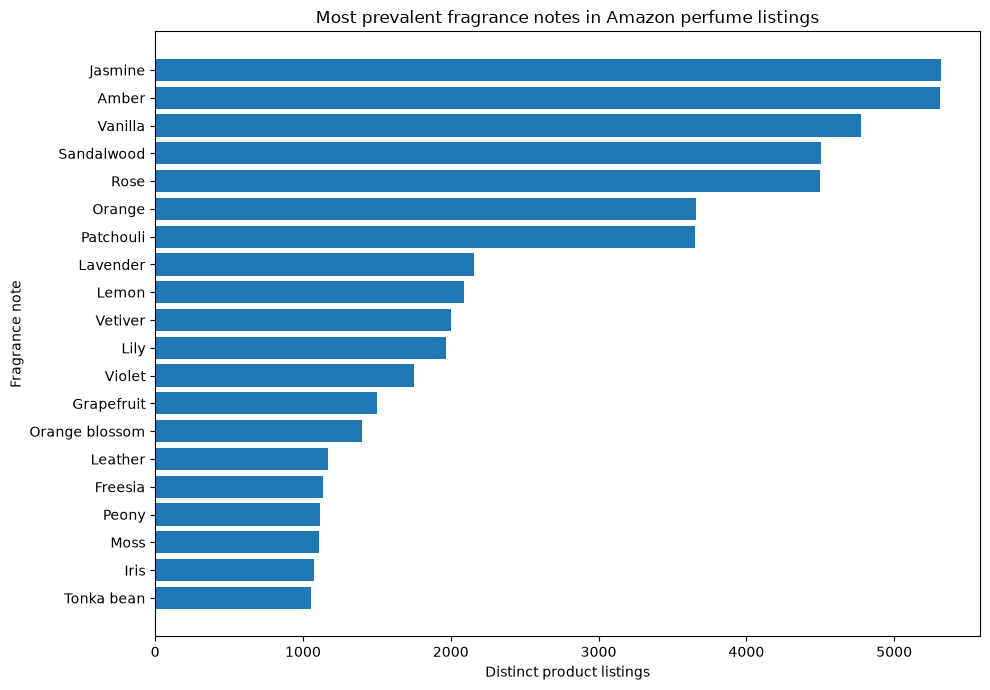

In [36]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_notes["note"][::-1],
    top_notes["matched_products"][::-1]
)

ax.set_title("Most prevalent fragrance notes in Amazon perfume listings")
ax.set_xlabel("Distinct product listings")
ax.set_ylabel("Fragrance note")

plt.tight_layout()
plt.show()

Notes drawn from [Parfumo's directory](https://www.parfumo.com/Fragrance_Notes), assigned to Amazon products on join based on whether the Parfumo term corresponds to 1-3-grams in the concatenated product title and description, and matched to Wikipedia articles for context.

### Proposal summary

Fill in the answers below. Refer to your outputs above rather than repeating them.

| Question | Your answer |
|---|---|
| Who is on your team, and how will you divide the work? | Just me, Jon. Doing it all myself. |
| Which tier are you targeting? | 93 |
| Which tables and document sources will you use? | Hu et al.'s (2024) [Amazon Product Reviews](https://amazon-reviews-2023.github.io/) data, specifically the Beauty and Personal Care product data. <br> Documentary sources include [Parfumo's](https://www.parfumo.com/) fragrance "notes" and categories directory, as well as Wikipedia pages corresponding to each material / ingredient / note / accord.  |
| What analytical questions will you investigate? | Which fragrance categories and notes correspond to historical Amazon perfume product listings? <br> Which of those categories-and-notes-as-linked-to-products receive consistently high reviewer attention, year-round? <br> Which is the "Scent for All Seasons"^TM? <br> Obversely, which categories-and-notes-as-linked-to-products receive relatively more *seasonal* reviewer attention (by quarter or month range)? <br> Do these "seasonal favorites" ever eclipse the "annual favorite(s)" in review volume? <br> Which categories-and-notes-as-linked-to-products receive the most positive, or the most negative, reviews overall? |


**Proposal: stop here. Continue to Phase 1 after completing Phase 0.**

## Phase 1: Embeddings and semantic search

<a id="scrollTo=phase-1"></a>


In [37]:
# @title Compute MiniLM embeddings
from sentence_transformers import SentenceTransformer
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Embedding device:", DEVICE)
embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
def make_passages(articles, embedder):
    tok = embedder.tokenizer
    size = embedder.max_seq_length - tok.num_special_tokens_to_add(pair=False) - 8
    assert size > 0
    rows = []
    for article in articles.sort_values("id").to_dict("records"):
        tokens = tok.encode(article["text"], add_special_tokens=False)
        offset = 0
        while offset < len(tokens):
            count = min(size, len(tokens) - offset)
            text = tok.decode(tokens[offset:offset+count], skip_special_tokens=True)
            # Keep all source tokens: move unused tokens to the next passage.
            while len(tok.encode(text, add_special_tokens=True)) > embedder.max_seq_length:
                count -= 1
                if count <= 0:
                    raise ValueError("A source token cannot fit in the embedding context")
                text = tok.decode(tokens[offset:offset+count], skip_special_tokens=True)
            if text.strip():
                rows.append({"document_id": str(article["id"]),
                    "passage_id": f'{article["id"]}:{offset}', "title": article["title"],
                    "url": article["url"], "text": text})
            offset += count
    return pd.DataFrame(rows)
if (WORK / "articles.parquet").exists():
    passages = make_passages(pd.read_parquet(WORK / "articles.parquet"), embedder)

    #Add section for implementing keyword segmentation
    pattern = r"\b(?:" + "|".join(
        re.escape(k.lower()) for k in EXT_KEYWORDS
        ) + r")\b"

    passages["scent_relevant"] = passages["text"].str.contains(
        pattern, case=False, regex=True, na=False
        )
    print("Scent-focused passages:", passages.scent_relevant.sum())
    print("Other passages:", (~passages.scent_relevant).sum())
    # Rather than filtering Wikipedia articles by keywords, filter segments of articles by keyword
    # Can always walk the filter back from segments to articles

    # Retain only scent-relevant passages for embedding
    #passages = passages.loc[passages["scent_relevant"]].reset_index(drop=True)
    #print("Chunks reduced to:", passages.sum(), "passages.")

    print(f"Embedding {len(passages):,} passages.")
    if len(passages) > 20_000:
        print("Large collection: embedding may take longer. Relevant sections can reduce runtime.")
    t0 = time.perf_counter()
    vectors = embedder.encode(passages.text.tolist(), batch_size=32, normalize_embeddings=True)
    assert vectors.shape == (len(passages), 384) and np.isfinite(vectors).all()
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)
    passages["embedding"] = vectors.tolist()
    passages.to_parquet(WORK / "passages.parquet", index=False)
    print("Passages:", len(passages), "Embedding seconds:", time.perf_counter()-t0)


/Users/jball/Work/a-scent-for-all-seasons/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1120 20:04:37.044000 6174 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Embedding device: cpu


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 6025.46it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1619 > 256). Running this sequence through the model will result in indexing errors


Scent-focused passages: 1732
Other passages: 2599
Embedding 4,331 passages.
Passages: 4331 Embedding seconds: 31.118836916983128


In [38]:
print(passages.shape)
print(passages.columns.tolist())

(4331, 7)
['document_id', 'passage_id', 'title', 'url', 'text', 'scent_relevant', 'embedding']


In [39]:
# Load Wikipedia passages into DuckDB, specifying FLOAT for embeddings
con.execute("""
    CREATE OR REPLACE TABLE wiki_passages AS
    SELECT
        document_id,
        passage_id,
        title,
        url,
        text,
        scent_relevant,
        embedding::FLOAT[384] AS embedding
    FROM read_parquet(?)
""", [str(WORK / "passages.parquet")])

con.execute("""
    SELECT
        COUNT(*) AS n_passages,
        COUNT(DISTINCT document_id) AS n_documents,
        array_length(embedding) AS embedding_dim
    FROM wiki_passages
    GROUP BY embedding_dim
""").df()

,n_passages,n_documents,embedding_dim
0,4331,291,384


In [40]:
con.execute("DESCRIBE wiki_passages").df()

,column_name,column_type,null,key,default,extra
0,document_id,VARCHAR,YES,None,None,None
1,passage_id,VARCHAR,YES,None,None,None
2,title,VARCHAR,YES,None,None,None
3,url,VARCHAR,YES,None,None,None
4,text,VARCHAR,YES,None,None,None
5,scent_relevant,BOOLEAN,YES,None,None,None
6,embedding,FLOAT[384],YES,None,None,None


In [41]:
query = "Which fragrance notes are associated with summer and warm weather?"

query_vec = embedder.encode(
    query,
    normalize_embeddings=True
).tolist()

In [42]:
results = con.execute("""
    SELECT
        title,
        url,
        text,
        array_cosine_similarity(
            embedding,
            ?::FLOAT[384]
        ) AS similarity
    FROM wiki_passages
    ORDER BY similarity DESC
    LIMIT 10
""", [query_vec]).df()

results.head(10)

,title,url,text,similarity
0,Cyclamen,https://en.wikipedia.org/wiki/Cyclamen,##s over 100 registered cultivars. cyclamen fl...,0.449480
1,Pelargonium,https://en.wikipedia.org/wiki/Pelargonium,") ' lara starshine ' ( aromatic leaves, lilac ...",0.418128
2,Pelargonium,https://en.wikipedia.org/wiki/Pelargonium,in cooking. occasionally scented types can be ...,0.413860
3,Cananga odorata,https://en.wikipedia.org/wiki/Cananga_odorata,"full or partial sun, and prefers the acidic so...",0.413307
4,Agathosma,https://en.wikipedia.org/wiki/Agathosma,. this is not particularly unusual in reaction...,0.412358
5,Saffron,https://en.wikipedia.org/wiki/Saffron,"##nal, a volatile oil, gives saffron much of i...",0.409312
6,Cinnamon,https://en.wikipedia.org/wiki/Cinnamon,and spices = = notes = = = = references = = = ...,0.405842
7,Coriander,https://en.wikipedia.org/wiki/Coriander,"##ata is commonly called vietnamese coriander,...",0.401373
8,Pelargonium,https://en.wikipedia.org/wiki/Pelargonium,"hybrid uniques, have been crossed with regal p...",0.396289
9,Ambergris,https://en.wikipedia.org/wiki/Ambergris,chicago : university of chicago press. pp. 8 –...,0.390653


Not bad. Not sure.

In [43]:
print(repr(results.iloc[0]["text"]))

'##s over 100 registered cultivars. cyclamen flowers have a subtle scent that is reminiscent of both lily - of - the - valley and rose. the cyclamen note is used in perfumery to give clean, watercolour - like scent. an example of a perfume with a leading cyclamen note is masaki shiro by the japanese brand masaki matsushima. = = = hardiness = = = cyclamen species range from frost - hardy to frost - tender. the most frost - hardy species, such as c. coum, c. hederifolium, c. parviflorum, and c. purpurascens, tolerate temperatures down to −18 °c ( 0 °f ), to even −30 °c ( −22 °f ) when growing in well - drained soil and protected by snow cover. c. repandum survives temperatures down to −14 °c ( 7 °f ) but not prolonged freezing below this temperature. c. graecum tolerates frost as low as −4 °c ( 25 °f ) for a few hours. others, such as c. africanum, c. persicum and c. rohlfsianum, tolerate only'


The chunking could be better. But if multiple relevant chunks are retrieved into context, then it's not worth spending more time on. Wikipedia isn't really adding much anyway.

In [44]:
con.sql("""
    SELECT
        COUNT(*) AS passages,
        COUNT(DISTINCT document_id) AS documents,
        COUNT(*) FILTER (WHERE scent_relevant) AS scent_passages,
        MIN(array_length(embedding)) AS min_dim,
        MAX(array_length(embedding)) AS max_dim
    FROM wiki_passages
""").show()

┌──────────┬───────────┬────────────────┬─────────┬─────────┐
│ passages │ documents │ scent_passages │ min_dim │ max_dim │
│  int64   │   int64   │     int64      │  int64  │  int64  │
├──────────┼───────────┼────────────────┼─────────┼─────────┤
│     4331 │       291 │           1732 │     384 │     384 │
└──────────┴───────────┴────────────────┴─────────┴─────────┘



## Checkpoint

Write:

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import duckdb

DB = DATA / "fragrance.duckdb"
ZIP = Path("nanoquery_checkpoint.zip")

# Verify required tables and columns
required = [
    "eaux",
    "perfume_reviews",
    "fragrance_notes",
    "fragrance_note_matches",
    "wiki_passages",
]

for table in required:
    count = con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    assert count > 0, f"Missing or empty table: {table}"
    print(f"{table}: {count:,} rows")

review_columns = {
    row[1] for row in con.execute("PRAGMA table_info('perfume_reviews')").fetchall()
}
assert {"title", "text"} <= review_columns, (
    "Rebuild perfume_reviews with review title and text before export"
)

support_files = [
    WORK / "wiki_extract.parquet",
    WORK / "articles.parquet",
    WORK / "passages.parquet",
    WORK / "article_relevance.csv",
    WORK / "collection_report.json",
]

for path in support_files[:3]:
    assert path.exists(), f"Missing required checkpoint file: {path}"

# Flush and close database before archiving
con.execute("CHECKPOINT")
con.close()

with ZipFile(ZIP, "w", compression=ZIP_DEFLATED, compresslevel=3) as z:
    z.write(DB, arcname=DB.as_posix())
    for path in support_files:
        if path.exists():
            z.write(path, arcname=path.as_posix())

with ZipFile(ZIP) as z:
    assert z.testzip() is None
    print("\nArchive contents:")
    for name in z.namelist():
        print(name)

print(f"\nCheckpoint size: {ZIP.stat().st_size / 1024**3:.2f} GiB")

files.download(str(ZIP))

Read:

In [ ]:
from google.colab import files
from zipfile import ZipFile
from pathlib import Path
import duckdb

files.upload()  # nanoquery_checkpoint.zip

with ZipFile("nanoquery_checkpoint.zip") as z:
    assert z.testzip() is None
    z.extractall(".")

DATA = Path("amazon_reviews")
WORK = Path("p2_work")

con = duckdb.connect(str(DATA / "fragrance.duckdb"))

print(con.sql("SHOW TABLES").df())
print(con.sql("""
    SELECT COUNT(*) AS passages
    FROM wiki_passages
""").df())

In [ ]:
from pathlib import Path
import duckdb

DATA = Path("amazon_reviews")
WORK = Path("p2_work")

con = duckdb.connect(str(DATA / "fragrance.duckdb"))

display(con.sql("SHOW TABLES").df())
display(con.sql("""
    SELECT COUNT(*) AS passages
    FROM wiki_passages
""").df())

## Section 1: Analytical SQL and charts

Complete five analytical queries and three charts in total. Reuse your proposal query and chart if they meet these requirements.

Each query must combine at least two of: joins, CTEs, window functions, subqueries, CASE-based analysis, or semantic retrieval. CASE-based analysis applies a classification or calculation used in the answer. Semantic retrieval followed by a join counts as two techniques.

Give each chart a title, labeled axes, and a short caption. Keep your checks and results visible.


In [45]:
import matplotlib.pyplot as plt

In [46]:
ANALYTICAL_QUERIES = []

In [47]:
# All 372 matched notes
MEMBERSHIP = """
SELECT DISTINCT parent_asin, 'note' AS kind, note AS scent
FROM fragrance_note_matches
WHERE parent_asin IS NOT NULL AND note IS NOT NULL
UNION ALL
SELECT DISTINCT parent_asin, 'category' AS kind, category AS scent
FROM fragrance_note_matches
WHERE parent_asin IS NOT NULL AND category IS NOT NULL
"""

In [48]:
# 2003 starts Jan 20; 2023 ends Sep 12, so exclude both from quarters
# Require baselines coverage across all four quarters of each included year
TIME_CTES = f"""
WITH review_dates AS (
    SELECT parent_asin, user_id, rating, verified_purchase,
           EXTRACT(YEAR FROM epoch_ms(timestamp))::INTEGER AS yr,
           EXTRACT(QUARTER FROM epoch_ms(timestamp))::INTEGER AS qtr
    FROM perfume_reviews
    WHERE timestamp IS NOT NULL
),
valid_years AS (
    SELECT yr
    FROM review_dates
    WHERE yr BETWEEN 2004 AND 2022
    GROUP BY yr
    HAVING COUNT(*) >= 1000 AND COUNT(DISTINCT qtr) = 4
),
reviews AS (
    SELECT r.* FROM review_dates r JOIN valid_years y USING (yr)
),
quarter_totals AS (
    SELECT yr, qtr, COUNT(*) AS all_reviews
    FROM reviews GROUP BY yr, qtr
),
member AS (
    {MEMBERSHIP}
),
entity_counts AS (
    SELECT m.kind, m.scent, r.yr, r.qtr,
           COUNT(*) AS n_reviews
    FROM member m JOIN reviews r USING (parent_asin)
    GROUP BY m.kind, m.scent, r.yr, r.qtr
),
entity_breadth AS (
    SELECT m.kind, m.scent,
           COUNT(*) AS reviews,
           COUNT(DISTINCT m.parent_asin) AS reviewed_products
    FROM member m JOIN reviews r USING (parent_asin)
    GROUP BY m.kind, m.scent
),
quarter_panel AS (
    SELECT b.kind, b.scent, t.yr, t.qtr,
           COALESCE(c.n_reviews, 0) AS n_reviews,
           t.all_reviews,
           COALESCE(c.n_reviews, 0)::DOUBLE / t.all_reviews AS review_share
    FROM entity_breadth b
    CROSS JOIN quarter_totals t
    LEFT JOIN entity_counts c
      ON c.kind = b.kind AND c.scent = b.scent
     AND c.yr = t.yr AND c.qtr = t.qtr
),
quarter_profiles AS (
    SELECT kind, scent, qtr,
           AVG(review_share) AS mean_share,
           SUM(n_reviews) AS quarter_reviews
    FROM quarter_panel
    GROUP BY kind, scent, qtr
)
"""

Q1

In [49]:
# Q1: fragance product classification, using the entire note / category set
q1_sql = f"""
WITH memberships AS ({MEMBERSHIP}),
counts AS (
    SELECT kind, scent, COUNT(DISTINCT parent_asin) AS products
    FROM memberships GROUP BY kind, scent
),
population AS (SELECT COUNT(DISTINCT parent_asin) AS products FROM eaux)
SELECT c.kind, c.scent, c.products,
       ROUND(100.0 * c.products / NULLIF(p.products, 0), 2) AS pct_all_perfumes,
       DENSE_RANK() OVER (PARTITION BY c.kind ORDER BY c.products DESC) AS prevalence_rank
FROM counts c CROSS JOIN population p
ORDER BY kind, prevalence_rank, scent
"""
ANALYTICAL_QUERIES.append(q1_sql)
q1 = con.execute(q1_sql).df()
assert not q1.duplicated(["kind", "scent"]).any()
assert (q1.products >= 0).all() and q1.pct_all_perfumes.between(0,100).all()
display(q1.groupby("kind", group_keys=False).head(15))

,kind,scent,products,pct_all_perfumes,prevalence_rank
0,category,Floral notes,14001,37.93,1
1,category,Citric notes,9751,26.41,2
2,category,Woody notes,9742,26.39,3
3,category,Oriental notes,8210,22.24,4
4,category,Spicy notes,5686,15.40,5
5,category,Amber,5383,14.58,6
6,category,Herbaceous notes,4349,11.78,7
7,category,Green notes,3892,10.54,8
8,category,Earthy notes,3669,9.94,9
9,category,Gourmandy notes,2178,5.90,10


Q2

In [50]:
# Q2: "Scent for All Seasons"
# quarterly maximin ranking
q2_sql = TIME_CTES + """,
annual_presence AS (
    SELECT kind, scent, yr,
           COUNT(*) FILTER (WHERE n_reviews > 0) AS quarters_with_reviews,
           SUM(n_reviews) AS yearly_reviews
    FROM quarter_panel GROUP BY kind, scent, yr
),
consistency AS (
    SELECT kind, scent,
           COUNT(*) FILTER (WHERE yearly_reviews >= 10) AS active_years,
           COUNT(*) FILTER (WHERE quarters_with_reviews = 4) AS all_four_quarter_years
    FROM annual_presence GROUP BY kind, scent
),
scored AS (
    SELECT b.kind, b.scent, b.reviews, b.reviewed_products,
           c.active_years, c.all_four_quarter_years,
           MIN(p.mean_share) AS min_quarter_share,
           AVG(p.mean_share) AS mean_quarter_share,
           STDDEV_POP(p.mean_share) AS sd_quarter_share,
           MAX(p.mean_share) AS max_quarter_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 1) AS q1_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 2) AS q2_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 3) AS q3_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 4) AS q4_share
    FROM entity_breadth b JOIN quarter_profiles p
      ON p.kind = b.kind AND p.scent = b.scent
    JOIN consistency c ON c.kind = b.kind AND c.scent = b.scent
    GROUP BY b.kind, b.scent, b.reviews, b.reviewed_products,
             c.active_years, c.all_four_quarter_years
)
SELECT kind, scent, reviews, reviewed_products, active_years, all_four_quarter_years,
       ROUND(100 * min_quarter_share, 4) AS min_quarter_pct,
       ROUND(100 * mean_quarter_share, 4) AS mean_quarter_pct,
       ROUND(sd_quarter_share / NULLIF(mean_quarter_share, 0), 4) AS cv_quarters,
       ROUND(100 * q1_share, 4) AS q1_pct,
       ROUND(100 * q2_share, 4) AS q2_pct,
       ROUND(100 * q3_share, 4) AS q3_pct,
       ROUND(100 * q4_share, 4) AS q4_pct,
       DENSE_RANK() OVER (PARTITION BY kind ORDER BY min_quarter_share DESC) AS all_seasons_rank
FROM scored
WHERE reviews >= 100 AND reviewed_products >= 5
  AND active_years >= 3 AND all_four_quarter_years >= 2
ORDER BY kind, all_seasons_rank, scent
"""
ANALYTICAL_QUERIES.append(q2_sql)
q2 = con.execute(q2_sql).df()
assert len(q2) > 0, "No qualifying years or notes"
assert q2.min_quarter_pct.between(0,100).all()
assert (q2.min_quarter_pct <= q2.mean_quarter_pct + 1e-3).all()
print("Year-round favorites, by quarterly product-review freq (maximin):")
display(q2.groupby("kind", group_keys=False).head(12))
print("\nYear-round favorites, by product-review consistency across quarters (quarterly coeff of var):")
display(q2[(q2.kind == "note") & (q2.reviews >= 50000)].sort_values("cv_quarters").head(10))

Year-round favorites, by quarterly product-review freq (maximin):


,kind,scent,reviews,reviewed_products,active_years,all_four_quarter_years,min_quarter_pct,mean_quarter_pct,cv_quarters,q1_pct,q2_pct,q3_pct,q4_pct,all_seasons_rank
0,category,Floral notes,350476,13320,15,15,42.2317,42.6750,0.0092,42.3378,43.1286,42.2317,43.0019,1
1,category,Woody notes,279388,9236,15,15,32.5978,33.3336,0.0176,33.3897,33.1274,32.5978,34.2196,2
2,category,Citric notes,264196,9274,15,15,30.6655,31.0473,0.0139,30.9030,30.8418,30.6655,31.7789,3
3,category,Oriental notes,207672,7765,15,15,24.0637,24.6202,0.0230,24.7676,24.1672,24.0637,25.4822,4
4,category,Amber,167525,5059,15,15,18.7593,18.9974,0.0132,18.8823,18.9290,18.7593,19.4188,5
5,category,Herbaceous notes,152100,4134,15,15,18.3778,18.8427,0.0192,18.8298,18.3778,18.7707,19.3927,6
6,category,Spicy notes,158884,5366,15,15,18.3640,19.0407,0.0242,19.0200,18.3640,19.1156,19.6633,7
7,category,Green notes,101632,3695,15,15,11.7269,12.0232,0.0171,11.7269,12.2740,12.1407,11.9511,8
8,category,Earthy notes,99916,3461,15,15,11.3895,11.7990,0.0313,11.9588,11.3895,11.5243,12.3235,9
9,category,Gourmandy notes,54477,2060,15,15,6.1650,6.3079,0.0226,6.1854,6.5145,6.1650,6.3666,10



Year-round favorites, by product-review consistency across quarters (quarterly coeff of var):


,kind,scent,reviews,reviewed_products,active_years,all_four_quarter_years,min_quarter_pct,mean_quarter_pct,cv_quarters,q1_pct,q2_pct,q3_pct,q4_pct,all_seasons_rank
32,note,Orange,86653,3483,15,15,10.5638,10.7239,0.0098,10.6966,10.8134,10.5638,10.8220,8
38,note,Lily,52610,1888,15,15,6.0046,6.0775,0.0099,6.1192,6.0046,6.0347,6.1515,14
34,note,Lemon,67406,1974,15,15,7.9194,8.0375,0.0119,7.9194,8.0175,8.0268,8.1864,10
39,note,Pepper,51770,1790,15,15,5.5892,5.6408,0.0126,5.6140,5.5892,5.5972,5.7626,15
36,note,Lavender,58888,2031,15,15,7.5939,7.7349,0.0129,7.6993,7.7831,7.8633,7.5939,12
37,note,Woods,58543,1795,15,15,7.1315,7.2476,0.0135,7.1315,7.3218,7.1729,7.3642,13
25,note,Amber,166531,4994,15,15,18.6603,18.8861,0.0136,18.7924,18.7679,18.6603,19.3237,1
33,note,Cedar,85793,2501,15,15,9.5055,9.7432,0.0163,9.7865,9.5055,9.7331,9.9479,9
30,note,Rose,99643,4246,15,15,11.5420,11.9239,0.0226,11.5420,12.2727,11.8375,12.0435,6
29,note,Vanilla,106921,4492,15,15,11.7438,12.1811,0.0235,12.1835,12.2541,11.7438,12.5430,5


Q3

In [51]:
# Q3: Rank notes and categories by seasonal "lift" : highest quarterly review share / average quarterly review share
# & measure how consistently the peak quarter recurs across years
q3_sql = TIME_CTES + """,
profile AS (
    SELECT b.kind, b.scent, b.reviews, b.reviewed_products,
           AVG(p.mean_share) AS mean_share,
           MAX(p.mean_share) AS max_share,
           MIN(p.mean_share) AS min_share,
           MAX_BY(p.qtr, p.mean_share) AS preferred_quarter,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 1) AS q1_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 2) AS q2_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 3) AS q3_share,
           MAX(p.mean_share) FILTER (WHERE p.qtr = 4) AS q4_share
    FROM entity_breadth b JOIN quarter_profiles p
      ON p.kind = b.kind AND p.scent = b.scent
    GROUP BY b.kind, b.scent, b.reviews, b.reviewed_products
),
yearly AS (
    SELECT *,
       SUM(n_reviews) OVER (PARTITION BY kind, scent, yr) AS yearly_reviews,
       ROW_NUMBER() OVER (PARTITION BY kind, scent, yr
                          ORDER BY review_share DESC, qtr) AS qtr_rank
    FROM quarter_panel
),
repeat_stats AS (
    SELECT p.kind, p.scent,
           COUNT(*) FILTER (WHERE y.qtr_rank = 1 AND y.yearly_reviews >= 10)
             AS active_years,
           COUNT(*) FILTER (WHERE y.qtr_rank = 1 AND y.yearly_reviews >= 10
                              AND y.qtr = p.preferred_quarter) AS peak_years
    FROM profile p JOIN yearly y ON p.kind = y.kind AND p.scent = y.scent
    GROUP BY p.kind, p.scent
)
SELECT p.kind, p.scent, p.reviews, p.reviewed_products,
       p.preferred_quarter,
       ROUND(p.max_share / NULLIF(p.mean_share, 0), 3) AS seasonal_lift,
       r.peak_years, r.active_years,
       ROUND(100.0 * r.peak_years / NULLIF(r.active_years, 0), 1) AS peak_repeat_pct,
       ROUND(100 * p.q1_share, 4) AS q1_pct,
       ROUND(100 * p.q2_share, 4) AS q2_pct,
       ROUND(100 * p.q3_share, 4) AS q3_pct,
       ROUND(100 * p.q4_share, 4) AS q4_pct
FROM profile p JOIN repeat_stats r USING (kind, scent)
WHERE p.reviews >= 100 AND p.reviewed_products >= 5 AND r.active_years >= 3
  AND 2 * r.peak_years >= r.active_years
ORDER BY kind, seasonal_lift DESC, peak_years DESC, scent
"""
ANALYTICAL_QUERIES.append(q3_sql)
q3 = con.execute(q3_sql).df()
assert (q3.peak_years <= q3.active_years).all()
assert (q3.seasonal_lift >= 1 - 1e-3).all()
display(q3.groupby("kind", group_keys=False).head(12))

,kind,scent,reviews,reviewed_products,preferred_quarter,seasonal_lift,peak_years,active_years,peak_repeat_pct,q1_pct,q2_pct,q3_pct,q4_pct
0,category,Animalic notes,46081,1442,4,1.052,8,15,53.3,4.5245,4.5768,4.7029,4.9243
1,category,Fruity notes,30313,1199,1,1.044,9,15,60.0,3.9694,3.7724,3.6027,3.8649
2,category,Oriental notes,207672,7765,4,1.035,9,15,60.0,24.7676,24.1672,24.0637,25.4822
3,category,Spicy notes,158884,5366,4,1.033,9,15,60.0,19.0200,18.3640,19.1156,19.6633
4,note,Sunflower,123,13,2,1.631,2,3,66.7,0.0169,0.0248,0.0101,0.0090
5,note,Jojoba,1324,100,4,1.598,6,11,54.5,0.1050,0.1262,0.1623,0.2619
6,note,Oleander,137,12,2,1.477,3,5,60.0,0.0345,0.0508,0.0347,0.0175
7,note,Agarwood / Oud,709,67,4,1.438,7,8,87.5,0.0354,0.0422,0.0551,0.0745
8,note,Metallic notes,179,6,3,1.382,2,4,50.0,0.0102,0.0144,0.0177,0.0089
9,note,Grasses,608,27,3,1.376,7,11,63.6,0.0635,0.0442,0.0988,0.0807


In [52]:
# sensitivity check
# compare seasonal rankings using two denominators : all perfume reviews vs. reviews of Parfumo-matched products only
original_totals = """quarter_totals AS (
    SELECT yr, qtr, COUNT(*) AS all_reviews
    FROM reviews GROUP BY yr, qtr
)"""

matched_totals = """quarter_totals AS (
    SELECT yr, qtr, COUNT(*) AS all_reviews
    FROM reviews
    WHERE parent_asin IN (
        SELECT DISTINCT parent_asin
        FROM fragrance_note_matches
    )
    GROUP BY yr, qtr
)"""

assert TIME_CTES.count(original_totals) == 1

q3_matched_sql = q3_sql.replace(
    original_totals, matched_totals, 1
)

q3_matched = con.execute(q3_matched_sql).df()

comparison = q3.merge(
    q3_matched[
        ["kind", "scent", "preferred_quarter",
         "seasonal_lift", "peak_repeat_pct"]
    ],
    on=["kind", "scent"],
    suffixes=("_all", "_matched")
)

comparison["peak_changed"] = (
    comparison.preferred_quarter_all
    != comparison.preferred_quarter_matched
)

print("Q3 denominator sensitivity:")
display(
    comparison[
        (comparison.kind == "note")
        & (comparison.reviews >= 1000)
        & (comparison.peak_repeat_pct_all >= 50)
    ][[
        "scent", "reviews",
        "preferred_quarter_all",
        "preferred_quarter_matched",
        "seasonal_lift_all",
        "seasonal_lift_matched",
        "peak_repeat_pct_all",
        "peak_repeat_pct_matched",
        "peak_changed"
    ]].sort_values("reviews", ascending=False).head(20)
)

Q3 denominator sensitivity:


,scent,reviews,preferred_quarter_all,preferred_quarter_matched,seasonal_lift_all,seasonal_lift_matched,peak_repeat_pct_all,peak_repeat_pct_matched,peak_changed
27,Jasmine,155093,1,1,1.025,1.036,53.3,53.3,False
26,Mandarin,61488,1,1,1.027,1.038,66.7,53.3,False
20,Sage,39621,4,4,1.111,1.102,66.7,60.0,False
25,Leather,32505,4,4,1.035,1.026,53.3,53.3,False
24,Orchid,30719,1,1,1.043,1.053,53.3,53.3,False
18,Saffron,11894,4,4,1.130,1.120,61.5,61.5,False
16,Ambergris,10888,4,4,1.146,1.138,53.8,53.8,False
23,Citron,6369,4,4,1.045,1.034,54.5,54.5,False
13,Plastic,5234,3,3,1.192,1.199,50.0,50.0,False
22,Birch,4313,3,3,1.084,1.084,50.0,58.3,False


Q4

In [53]:
# Q4: Compare quarterly review counts for the top year-round note (the scent for all seasons)
# against high review-volume seasonal notes (the scents for *a* season)
MIN_LIFT, MIN_PEAK_YEARS, MIN_REPEAT_PCT = 1.20, 2, 50  # researcher-chosen; chance repeat ~25%

def sql_lit(s):
    return "'" + str(s).replace("'", "''") + "'"

notes2 = q2[q2.kind == "note"].sort_values(["all_seasons_rank", "scent"])
assert len(notes2) > 0, "No note meets Q2 thresholds; inspect Q2 rather than lowering ad hoc"
annual_note = str(notes2.iloc[0]["scent"])


notes3 = q3[
    (q3.kind == "note")
    & (q3.scent != annual_note)
    & (q3.seasonal_lift >= 1.20)
]

seasonal_notes = (
    notes3.sort_values("reviews", ascending=False)
    ["scent"].astype(str).tolist()
)
seasonal_arr = "[" + ", ".join(map(sql_lit, seasonal_notes)) + "]" 

# ;iterals are escaped
q4_sql = TIME_CTES + f""",
selected AS (
    SELECT UNNEST({seasonal_arr}::VARCHAR[]) AS seasonal_note
),
shared AS (   -- reviews of products matching BOTH notes (counted in both totals)
    SELECT s.seasonal_note, r.yr, r.qtr, COUNT(*) AS shared_reviews
    FROM selected s
    JOIN member ms ON ms.kind = 'note' AND ms.scent = s.seasonal_note
    JOIN member ma ON ma.kind = 'note' AND ma.scent = {sql_lit(annual_note)}
                  AND ma.parent_asin = ms.parent_asin
    JOIN reviews r ON r.parent_asin = ms.parent_asin
    GROUP BY s.seasonal_note, r.yr, r.qtr
),
comparisons AS (
    SELECT s.seasonal_note, t.yr, t.qtr,
           COALESCE(a.n_reviews, 0)       AS annual_reviews,
           COALESCE(x.n_reviews, 0)       AS seasonal_reviews,
           COALESCE(sh.shared_reviews, 0) AS shared_reviews
    FROM selected s CROSS JOIN quarter_totals t
    LEFT JOIN entity_counts a
      ON a.kind = 'note' AND a.scent = {sql_lit(annual_note)}
     AND a.yr = t.yr AND a.qtr = t.qtr
    LEFT JOIN entity_counts x
      ON x.kind = 'note' AND x.scent = s.seasonal_note
     AND x.yr = t.yr AND x.qtr = t.qtr
    LEFT JOIN shared sh
      ON sh.seasonal_note = s.seasonal_note AND sh.yr = t.yr AND sh.qtr = t.qtr
)
SELECT seasonal_note, yr, qtr, annual_reviews, seasonal_reviews, shared_reviews,
       CASE WHEN seasonal_reviews > annual_reviews THEN 'seasonal'
            WHEN seasonal_reviews = annual_reviews THEN 'tie'
            ELSE 'annual' END AS leader
FROM comparisons
ORDER BY seasonal_note, yr, qtr
"""
ANALYTICAL_QUERIES.append(q4_sql)
q4 = con.execute(q4_sql).df()

print("The scent for all seasons:", annual_note)
if seasonal_notes:
    assert (q4[["annual_reviews", "seasonal_reviews", "shared_reviews"]] >= 0).all().all()
    assert (q4.shared_reviews <= q4[["annual_reviews", "seasonal_reviews"]].min(axis=1)).all()
    print("Scents for *a* season:", ", ".join(seasonal_notes))
    display(q4.groupby("seasonal_note").agg(
        year_quarters=("leader", "size"),
        eclipse_quarters=("leader", lambda s: int((s == "seasonal").sum())),
        eclipse_years=("yr", lambda y: int(y[q4.loc[y.index, "leader"] == "seasonal"].nunique())),
        annual_reviews=("annual_reviews", "sum"),
        seasonal_reviews=("seasonal_reviews", "sum"),
        shared_reviews=("shared_reviews", "sum")).reset_index())
    display(q4[q4.leader == "seasonal"].head(20))
else:
    print(f'No note meets lift>={MIN_LIFT}, peak_years>={MIN_PEAK_YEARS}, '
          f'repeat>={MIN_REPEAT_PCT}%: no eclipse under this definition (a finding, not an error).')

The scent for all seasons: Amber
Scents for *a* season: Jojoba, Wisteria, Resins, Agarwood / Oud, Grasses, Datura, Atlas cedar, Maple, Soil, Metallic notes, Oleander, Sunflower


,seasonal_note,year_quarters,eclipse_quarters,eclipse_years,annual_reviews,seasonal_reviews,shared_reviews
0,Agarwood / Oud,60,0,0,166531,709,549
1,Atlas cedar,60,0,0,166531,577,43
2,Datura,60,0,0,166531,583,2
3,Grasses,60,0,0,166531,608,79
4,Jojoba,60,0,0,166531,1324,41
5,Maple,60,0,0,166531,376,31
6,Metallic notes,60,0,0,166531,179,2
7,Oleander,60,0,0,166531,137,9
8,Resins,60,0,0,166531,783,320
9,Soil,60,0,0,166531,257,0


,seasonal_note,yr,qtr,annual_reviews,seasonal_reviews,shared_reviews,leader


In [54]:
display(con.execute(TIME_CTES + """
SELECT t.qtr, ROUND(100 * AVG(m.n::DOUBLE / t.all_reviews), 2) AS matched_pct
FROM quarter_totals t
JOIN (SELECT yr, qtr, COUNT(*) AS n FROM reviews
      WHERE parent_asin IN (SELECT parent_asin FROM fragrance_note_matches)
      GROUP BY ALL) m USING (yr, qtr)
GROUP BY t.qtr ORDER BY t.qtr
""").df())

,qtr,matched_pct
0,1,60.96
1,2,61.62
2,3,61.54
3,4,62.10


In [55]:
print("Scents for *a* season (seasonal lift >= 1.20):")

display(
    q3[
        (q3["kind"] == "note")
        & (q3["seasonal_lift"] >= 1.20)
    ]
    .sort_values("reviews", ascending=False)
    .head(15)[
        [
            "scent",
            "reviews",
            "preferred_quarter",
            "seasonal_lift",
            "peak_repeat_pct",
        ]
    ]
)

Scents for *a* season (seasonal lift >= 1.20):


,scent,reviews,preferred_quarter,seasonal_lift,peak_repeat_pct
5,Jojoba,1324,4,1.598,54.5
11,Wisteria,1109,1,1.273,54.5
13,Resins,783,4,1.270,54.5
7,Agarwood / Oud,709,4,1.438,87.5
9,Grasses,608,3,1.376,63.6
12,Datura,583,1,1.271,50.0
14,Atlas cedar,577,3,1.259,60.0
10,Maple,376,4,1.282,55.6
15,Soil,257,3,1.229,60.0
8,Metallic notes,179,3,1.382,50.0


Q5

In [56]:
# Q5: Compare positive and negative review rates across fragrance notes and categories, proxied by frag descrips
q5_sql = f"""
WITH memberships AS ({MEMBERSHIP}),
rated AS (
    SELECT m.kind, m.scent, r.parent_asin, r.user_id,
           r.rating, r.verified_purchase
    FROM memberships m JOIN perfume_reviews r USING (parent_asin)
    WHERE r.rating IS NOT NULL AND r.rating BETWEEN 1 AND 5
),
summary AS (
    SELECT kind, scent,
           COUNT(*) AS rated_reviews,
           COUNT(DISTINCT parent_asin) AS reviewed_products,
           COUNT(DISTINCT user_id) AS distinct_reviewers,
           COUNT(*) FILTER (WHERE rating >= 4) AS positive_reviews,
           COUNT(*) FILTER (WHERE rating <= 2) AS negative_reviews,
           COUNT(*) FILTER (WHERE verified_purchase IS TRUE) AS verified_reviews,
           AVG(rating) AS mean_rating
    FROM rated GROUP BY kind, scent
)
SELECT kind, scent, rated_reviews, reviewed_products, distinct_reviewers,
       positive_reviews, negative_reviews, verified_reviews,
       ROUND(mean_rating, 3) AS mean_rating,
       ROUND(100.0 * positive_reviews / rated_reviews, 2) AS positive_pct,
       ROUND(100.0 * negative_reviews / rated_reviews, 2) AS negative_pct
FROM summary
WHERE rated_reviews >= 100 AND reviewed_products >= 5
ORDER BY kind, positive_pct DESC, rated_reviews DESC, scent
"""
ANALYTICAL_QUERIES.append(q5_sql)
q5 = con.execute(q5_sql).df()
assert ((q5.positive_reviews + q5.negative_reviews) <= q5.rated_reviews).all()
assert (q5.verified_reviews <= q5.rated_reviews).all()
print("Highest positive review prop:")
display(q5.groupby('kind', group_keys=False).head(10))
print("Highest negative review prop:")
display(q5.sort_values(["kind","negative_pct"], ascending=[True, False]).groupby('kind', group_keys=False).head(10))


Highest positive review prop:


,kind,scent,rated_reviews,reviewed_products,distinct_reviewers,positive_reviews,negative_reviews,verified_reviews,mean_rating,positive_pct,negative_pct
0,category,Fruity notes,32132,1264,30894,26098,4465,30178,4.301,81.22,13.90
1,category,Grain,840,83,818,677,113,774,4.300,80.60,13.45
2,category,Herbaceous notes,164097,4349,147040,131878,23865,155025,4.261,80.37,14.54
3,category,Balsamic notes,21021,841,20360,16853,3109,19736,4.257,80.17,14.79
4,category,Powdery notes,22617,1075,21766,18099,3470,21356,4.255,80.02,15.34
5,category,Green notes,109461,3892,101422,87486,16162,103142,4.250,79.92,14.77
6,category,Smoky notes,15551,598,15080,12421,2377,14657,4.245,79.87,15.29
7,category,Woody notes,301499,9741,263030,240737,45337,284394,4.246,79.85,15.04
8,category,Mossy notes,57738,1867,54630,46102,8636,54724,4.249,79.85,14.96
9,category,Tobacco,1333,47,1287,1063,180,1216,4.246,79.74,13.50


Highest negative review prop:


,kind,scent,rated_reviews,reviewed_products,distinct_reviewers,positive_reviews,negative_reviews,verified_reviews,mean_rating,positive_pct,negative_pct
24,category,Not classified,34019,1106,32850,25542,6351,31852,4.092,75.08,18.67
23,category,Textile notes,13681,473,13281,10381,2422,12773,4.132,75.88,17.70
21,category,Mineral notes,10669,255,10445,8235,1874,9944,4.141,77.19,17.56
22,category,Musk,2840,130,2772,2187,489,2657,4.141,77.01,17.22
20,category,Animalic notes,51839,1534,48545,40219,8810,49368,4.165,77.58,16.99
18,category,Aquatic notes,5098,130,5021,3991,831,4801,4.194,78.29,16.30
19,category,Gourmandy notes,59462,2177,56152,46438,9613,55695,4.193,78.10,16.17
17,category,Fragrance ingredients,12537,289,12161,9850,2007,11787,4.198,78.57,16.01
16,category,Resinous notes,52969,2026,50174,41774,8346,49928,4.216,78.86,15.76
15,category,Earthy notes,109321,3669,100222,86433,17156,103023,4.216,79.06,15.69


In [57]:
# top_product_share is the pct of reviews corresponding to the single most-reviewed product featuring a given note
concentration_sql = """
WITH product_note_reviews AS (
    SELECT
        m.note AS scent,
        r.parent_asin,
        COUNT(*) AS review_count
    FROM perfume_reviews r
    JOIN (
        SELECT DISTINCT parent_asin, note
        FROM fragrance_note_matches
    ) m USING (parent_asin)
    WHERE r.rating IS NOT NULL
    GROUP BY m.note, r.parent_asin
)
SELECT
    scent,
    COUNT(*) AS reviewed_products,
    SUM(review_count) AS reviews,
    ROUND(
        MAX(review_count)::DOUBLE
        / NULLIF(SUM(review_count), 0), 3
    ) AS top_product_share
FROM product_note_reviews
GROUP BY scent
HAVING SUM(review_count) >= 100
ORDER BY top_product_share DESC
"""

q5_concentration = con.execute(concentration_sql).df()

display(
    q5_concentration[
        q5_concentration.scent.isin(
            ["Ginseng", "Mineral amber", "Parsley",
             "Davana", "Plastic"]
        )
    ]
)

,scent,reviewed_products,reviews,top_product_share
4,Ginseng,9,402.0,0.913
15,Mineral amber,14,2049.0,0.771
16,Davana,36,660.0,0.770
32,Parsley,12,1054.0,0.620
57,Plastic,135,6056.0,0.516


In [58]:
# require at least 20 reviewed products
# and no single product contributing over 25% of reviews
q5_robust = q5.merge(
    q5_concentration[["scent", "top_product_share"]],
    on="scent",
    how="left"
)

q5_robust = q5_robust[
    (q5_robust["kind"] == "note")
    & (q5_robust["reviewed_products"] >= 20)
    & (q5_robust["top_product_share"] <= 0.25)
]

print("Most positive, diversified notes:")
display(q5_robust.nlargest(10, "positive_pct"))

print("Most negative, diversified notes:")
display(q5_robust.nlargest(10, "negative_pct"))

Most positive, diversified notes:


,kind,scent,rated_reviews,reviewed_products,distinct_reviewers,positive_reviews,negative_reviews,verified_reviews,mean_rating,positive_pct,negative_pct,top_product_share
45,note,Sweet pea,554,63,539,463,62,515,4.377,83.57,11.19,0.170
48,note,Pea,561,66,546,467,63,522,4.367,83.24,11.23,0.168
54,note,Myrrh,6211,177,6053,5155,744,5815,4.365,83.00,11.98,0.193
57,note,Teak,1122,85,1106,929,125,1050,4.365,82.80,11.14,0.234
58,note,Linen,814,70,800,674,101,754,4.369,82.80,12.41,0.117
59,note,Yuzu,8431,163,8158,6964,1158,8021,4.333,82.60,13.74,0.231
62,note,Juniper,17645,420,17106,14555,2297,16722,4.336,82.49,13.02,0.128
66,note,Berries,14670,524,14228,12063,1917,13827,4.339,82.23,13.07,0.188
73,note,Mimosa,7832,370,7581,6418,1025,7353,4.332,81.95,13.09,0.142
77,note,Basil,17783,538,17202,14548,2369,16805,4.316,81.81,13.32,0.079


Most negative, diversified notes:


,kind,scent,rated_reviews,reviewed_products,distinct_reviewers,positive_reviews,negative_reviews,verified_reviews,mean_rating,positive_pct,negative_pct,top_product_share
244,note,Narcissus,4047,154,3926,2853,980,3871,3.906,70.50,24.22,0.204
252,note,Wheat,167,30,162,116,38,158,3.910,69.46,22.75,0.180
246,note,Jojoba,1372,101,1296,967,304,1250,3.941,70.48,22.16,0.184
217,note,Hawthorn,263,38,260,198,58,241,4.030,75.29,22.05,0.167
230,note,Citrus fruits,798,84,788,582,175,749,3.986,72.93,21.93,0.128
238,note,Salt,2528,142,2487,1809,530,2354,3.968,71.56,20.97,0.198
234,note,Cotton,5741,174,5605,4143,1198,5450,4.008,72.17,20.87,0.098
220,note,Ambergris,13057,324,12584,9810,2543,12495,4.079,75.13,19.48,0.114
214,note,Pomelo,1367,72,1351,1032,266,1290,4.059,75.49,19.46,0.146
233,note,Agarwood / Oud,1117,80,1058,810,217,1056,3.987,72.52,19.43,0.134


In [59]:
# reviews overview
cohort_check = con.execute(TIME_CTES + """
SELECT MIN(yr) AS first_year, MAX(yr) AS last_year,
       COUNT(DISTINCT yr) AS eligible_years,
       COUNT(*) AS perfume_reviews_in_cohort
FROM reviews
""").df()
display(cohort_check)

,first_year,last_year,eligible_years,perfume_reviews_in_cohort
0,2008,2022,15,799384


In [60]:
# gender check
strata_sql = TIME_CTES + """,
selected AS (SELECT UNNEST(?::VARCHAR[]) AS scent),
note_products AS (
    SELECT DISTINCT m.parent_asin, m.scent
    FROM member m JOIN selected s ON m.scent = s.scent
    WHERE m.kind = 'note'
)
SELECT m.scent, COALESCE(e.gender_category, 'Unknown') AS gender_category,
       COALESCE(e.fragrance_type, 'Unknown') AS fragrance_type,
       COUNT(*) AS n_reviews, COUNT(DISTINCT m.parent_asin) AS n_products,
       ROUND(AVG(r.rating), 3) AS mean_rating
FROM note_products m JOIN eaux e USING (parent_asin)
JOIN reviews r USING (parent_asin)
GROUP BY m.scent, gender_category, fragrance_type
ORDER BY m.scent, n_reviews DESC
"""
strata = con.execute(strata_sql, [[annual_note] + seasonal_notes]).df()
print("gender + product type for popular notes")
display(strata)

gender + product type for popular notes


,scent,gender_category,fragrance_type,n_reviews,n_products,mean_rating
0,Agarwood / Oud,Women's,Eau de Parfum,351,38,4.125
1,Agarwood / Oud,Men's,Eau de Parfum,265,18,3.902
2,Agarwood / Oud,Men's,Eau de Toilette,69,4,3.913
3,Agarwood / Oud,Women's,Cologne,22,6,4.727
4,Agarwood / Oud,Men's,Cologne,2,1,5.000
5,Amber,Men's,Eau de Toilette,54519,1003,4.340
6,Amber,Women's,Eau de Parfum,49061,2061,4.174
7,Amber,Women's,Eau de Toilette,27742,902,4.300
8,Amber,Men's,Cologne,12181,369,4.350
9,Amber,Men's,Eau Fraiche,8772,16,4.195


In [61]:
assert len(ANALYTICAL_QUERIES) == 5

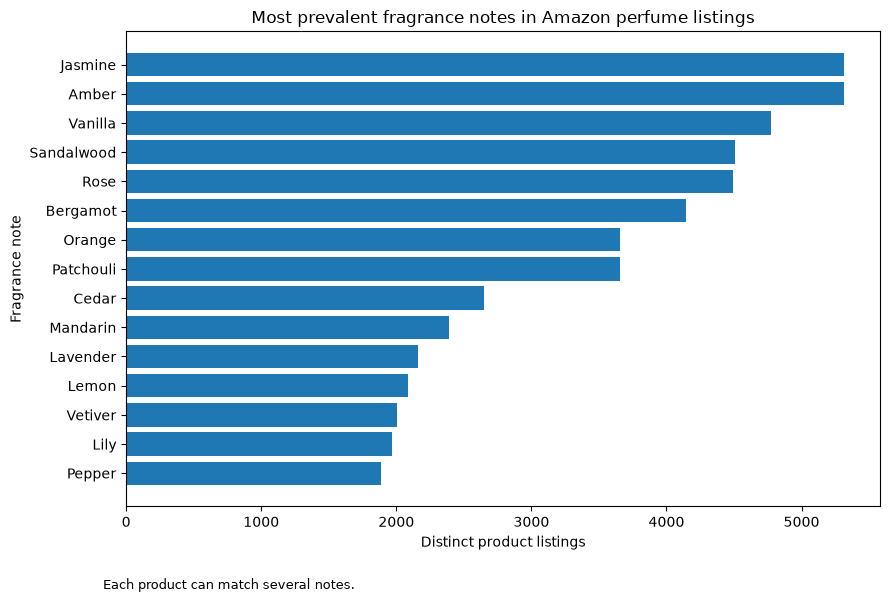

In [62]:
# Chart 1: all note matches, not restricted to Wikipedia availability.
fig, ax = plt.subplots(figsize=(9,6))
top = q1[q1.kind == "note"].sort_values("products",ascending=False).head(15).iloc[::-1]
ax.barh(top.scent, top.products)
ax.set_title("Most prevalent fragrance notes in Amazon perfume listings")
ax.set_xlabel("Distinct product listings")
ax.set_ylabel("Fragrance note")
fig.text(.12,.01,"Each product can match several notes.",fontsize=9)
fig.tight_layout(rect=(0,.05,1,1)); plt.show()

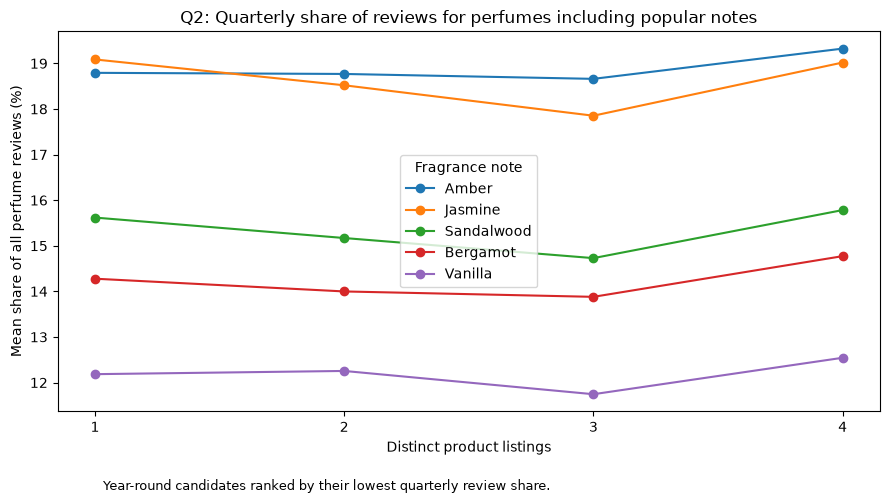

In [63]:
# Chart 2: normalized year-round quarterly attention among strongest candidates.
fig, ax = plt.subplots(figsize=(9,5))
for _, r in notes2.head(5).iterrows():
    ax.plot([1,2,3,4], [r[f'q{i}_pct'] for i in range(1,5)], marker='o',label=r.scent)
ax.set(title = "Q2: Quarterly share of reviews for perfumes including popular notes",
       xticks = [1,2,3,4])
ax.set_xlabel("Distinct product listings")
ax.set_ylabel("Mean share of all perfume reviews (%)")
ax.legend(title = "Fragrance note")
fig.text(.12,.01,'Year-round candidates ranked by their lowest quarterly review share.',fontsize=9)
fig.tight_layout(rect=(0,.05,1,1));plt.show()

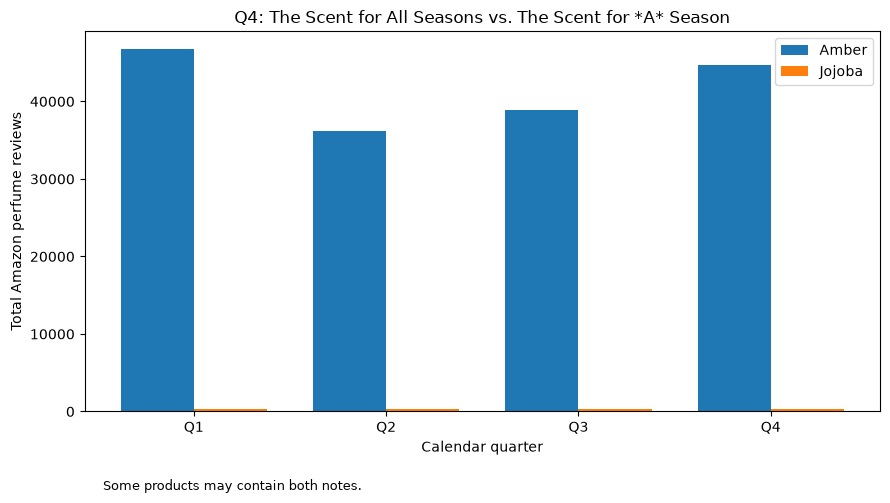

In [64]:
# Chart 3: review-volume eclipse test for the leading seasonal challenger.
challenger = seasonal_notes[0]
plot4 = q4[q4.seasonal_note == challenger].groupby("qtr")[["annual_reviews", "seasonal_reviews"]].sum().reindex([1,2,3,4],fill_value=0)
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(4);width=.38
ax.bar(x-width/2, plot4.annual_reviews, width,label=annual_note)
ax.bar(x+width/2, plot4.seasonal_reviews, width,label=challenger)
ax.set(title = "Q4: The Scent for All Seasons vs. The Scent for *A* Season",
       xticks = x,
       xticklabels = ["Q1", "Q2", "Q3", "Q4"])
ax.set_xlabel("Calendar quarter")
ax.set_ylabel("Total Amazon perfume reviews")
ax.legend()
fig.text(.12,.01, "Some products may contain both notes.",fontsize=9)
fig.tight_layout(rect=(0,.05,1,1));plt.show()

## Section 2: Documents and tables


In [65]:
# STUDENT WORK: use semantic retrieval for two of your five analytical queries.
# Save excerpts/source URLs, mappings, SQL/results, and checks for each.
# Map retrieved document IDs to IDs in your tables; bind those entity IDs as SQL parameters.
DOCUMENT_QUERY_CHECKS = []

pd.set_option("display.max_colwidth", 300)

def retrieve(queries, k=15, min_score=0.35):
    h = pd.concat([
        pd.DataFrame(search_passages(q, k=k)['rows']).assign(query=q)
        for q in queries
    ], ignore_index=True)
    return (h[h.similarity >= min_score]
            .sort_values("similarity", ascending=False)
            .drop_duplicates("passage_id"))

def map_docs(doc_ids):
    return con.execute("""
        SELECT document_id, article_title, document_url, requested_note AS note,
               COUNT(DISTINCT parent_asin) AS products
        FROM wiki_product_matches
        WHERE document_id IN (SELECT UNNEST(?::VARCHAR[]))
        GROUP BY ALL ORDER BY note""", [doc_ids]).df()

In [66]:
hits_a = retrieve([
    "flowers bloom in spring",
    "flowering in summer",
    "harvested in autumn",
    "used as a Christmas tree in winter"
])

hits_b = retrieve([
    "skin allergens restricted in perfumery",
    "fragrance ingredients causing allergic contact dermatitis",
    "natural fragrance materials subject to safety regulations",
    "animal-derived substances used in perfumery",
    "animal secretions used as perfume fixatives",
    "natural animal fragrance ingredients replaced by synthetics"
])
display(hits_a[["query", "similarity", "document_id", "title", "text"]])
display(hits_b[["query", "similarity", "document_id", "title", "text"]])

,query,similarity,document_id,title,text
45,used as a Christmas tree in winter,0.596256,19119938,Holly,", with the cultivar ' chestnut leaf '. = = = culture = = = holly – specifically the european holly, ilex aquifolium – is commonly referenced at christmas time, and is often referred to by the name christ ' s thorn. in many western christian cultures, holly is used as a traditional christmas deco..."
15,flowering in summer,0.544945,1680,Amaryllis,""" comes from the plant ' s pattern of flowering when the foliage has died down. this name is also used for other bulbs with a similar growth and flowering pattern ; some of these have their own widely used and accepted common names, such as the resurrection lily ( lycoris squamigera ). = = habit..."
30,harvested in autumn,0.527673,60951,Cardamom,"third year. cardamoms grown above 600 m ( 2, 000 ft ) elevation are considered to be of higher quality than those grown below that altitude. plants may be raised from seed or by division of the rhizome. in about a year, the seedlings reach about 30 cm ( 1 ft ) in length, and are ready for transp..."
16,flowering in summer,0.518056,1185479,Nerium,"to harvest the seeds, many gardeners choose to prune away the seedpods that form on spent flower clusters, which are a drain on energy. propagation can be made from cuttings, where they can readily root after being placed in water or in rich organic potting material, like compost. in mediterrane..."
17,flowering in summer,0.516829,3426696,Stephanotis,"some of the other spring flowering vines. it is known by a few different names such as "" madagascar jasmine "" and "" bridal veil "". = = species = = 15 species are accepted. formerly included transferred to other genera ( jasminanthes, marsdenia ) = = see also = = dregea sinensis = = references = ="
31,harvested in autumn,0.515618,59637,Crocus,"such as ' whitewell purple ' and ' ruby giant ' ), seed prolifically and are ideal for naturalizing. they can, however, become weeds in rock gardens, where they will often appear in the middle of choice, mat - forming alpine plants, and can be difficult to remove. crocus flowers and leaves are p..."
46,used as a Christmas tree in winter,0.513132,600841,Abies balsamea,"##sam fir can occur, which may significantly reduce radial growth. this can kill the tree. an outbreak in quebec in 1957 killed over 75 % of balsam fir in some stands. the needles of balsam fir can be infected by the fungus delphinella balsameae. balsam fir is also the most susceptible tree in e..."
47,used as a Christmas tree in winter,0.511370,600841,Abies balsamea,"used six times for the us capitol christmas tree between 1964 and 2019. = = = horticulture = = = abies balsamea is also grown as an ornamental tree for parks and gardens. very hardy down to −20 °c ( −4 °f ) or below, it requires a sheltered spot in full sun. the dwarf cultivar a. balsamea ' huds..."
18,flowering in summer,0.507375,40333,Magnolia,"soulangeana, is a hybrid of m. liliiflora and m. denudata. in the eastern united states, five native species are frequently in cultivation : m. acuminata ( as a shade tree ), m. grandiflora, m. virginiana, m. tripetala, and m. macrophylla. the last two species must be planted where high winds ar..."
19,flowering in summer,0.506357,407852,Hyacinth,"hyacinthus ( ) is a genus of bulbous herbs and spring - blooming perennials. they are fragrant flowering plants in the family asparagaceae, subfamily scilloideae and are commonly called hyacinths ( ). the genus is native predominantly to the eastern mediterranean region from the south of turkey ..."


,query,similarity,document_id,title,text
45,animal-derived substances used in perfumery,0.605971,1603731,Labdanum,"boiling the leaves and twigs. an absolute is also obtained by solvent extraction. an essential oil is produced by steam distillation. the raw gum is a black or sometimes dark brown, fragrant mass containing up to 20 % or more of water. it is plastic but not pourable, and becomes brittle with age..."
46,animal-derived substances used in perfumery,0.581226,1808135,Castoreum,"##oreum was also considered as an ingredient for the flavor and odor of cigarettes. medieval beekeepers used castoreum to increase honey production. = = related animal products = = taxea, a secretion of the badger ' s subcaudal glands comparable in its medicinal use to the better - known castore..."
47,animal-derived substances used in perfumery,0.568277,1808135,Castoreum,"##ylic acid, salicylaldehyde, and 3 - hydroxybenzoic acid. there are also oxygen - containing monoterpenes such as 6 - methyl - 1 - heptanol, 4, 6 - dimethyl - 1 - heptanol, isopinocamphone, pinocamphone, and two linalool oxides and their acetates. other compounds are : benzoic acid, benzyl alco..."
48,animal-derived substances used in perfumery,0.555595,1697,Ambergris,"soluble in ether, and in volatile and fixed oils. = = chemical properties = = ambergris is relatively nonreactive to acid. white crystals of a terpenoid known as ambrein, discovered by leopold ruzicka and fernand lardon in 1946, can be separated from ambergris by heating raw ambergris in alcohol..."
49,animal-derived substances used in perfumery,0.548032,1004103,Chamaecyparis obtusa,"the leaves of the plant. chamaecydin was first discovered in the seeds of c. obtusa. the essential oil of chamaecyparis obtusa contains a wide range of chemical compounds, including but not limited to the following : sabinene, elemol, myrcene, limonene, terpinen - 4 - ol, eudesmols, α - terpinyl..."
50,animal-derived substances used in perfumery,0.538858,29414816,Deer musk,"taste. according to encyclopædia britannica, "" a grain of musk will distinctly scent millions of cubic feet of air without any appreciable loss of weight, and its scent is not only more penetrating but also more persistent than that of any other known substance "". in addition to its odoriferous ..."
51,animal-derived substances used in perfumery,0.526919,12855043,Amyris,"is hard, heavy, close - grained, can take a high polish, and repels dry wood termites. essential oils containing caryophyllene, cadinene, and cadinol are extracted from a. balsamifera and a. elemifera. these are used in varnishes, perfumes, medicines, cosmetics, soaps, and incense. chemical comp..."
15,fragrance ingredients causing allergic contact dermatitis,0.520575,1697,Ambergris,"chicago : university of chicago press. pp. 8 – 16. isbn 978 - 0 - 226 - 43036 - 2. kovatcheva, assia ; golbraikh, alexander ; oloff, scott ; xiao, yun - de ; zheng, weifan ; wolschann, peter ; buchbauer, gerhard ; tropsha, alexander ( 2004 ). "" combinatorial qsar of ambergris fragrance compounds..."
52,animal-derived substances used in perfumery,0.518753,175254,Incense,"does not produce a perceptible smell. commercially, two types of incense base predominate : fuel and oxidizer mixtures : charcoal or wood powder provides the fuel for combustion while an oxidizer such as sodium nitrate or potassium nitrate sustains the burning of the incense. fragrant materials ..."
53,animal-derived substances used in perfumery,0.514061,3191150,Galbanum,". when diluted the scent of galbanum has variously been described as reminiscent of pine ( due to the pinene and limonene content ), evergreen, green bamboo, parsley, green apples, musk, or simply intense green. the oil has a pine like topnote which is less pronounced in the odor of the resinoid..."


In [67]:
pd.concat([
    hits_a.assign(analysis = "A"),
    hits_b.assign(analysis = "B")
], ignore_index=True).to_csv("section2_candidates.csv", index=False)

In [68]:
# document_id: (doc_quarter, verbatim excerpt)
# Northern Hemisphere: spring=Q2, summer=Q3, autumn/Christmas=Q4

VERIFIED_A = {
    "19119938": (4, "holly is used as a traditional christmas decoration"),
    "60951": (4, "the crop is accordingly gathered in october and november"),
    "600841": (4, "both varieties of the species are very popular as christmas trees"),
    "407852": (2, "hyacinthus ( ) is a genus of bulbous herbs and spring - blooming perennials"),
    "4649165": (4, "many maples have bright autumn foliage"),
    "56277": (2, "usually in mid - to late spring ( april or may in the northern hemisphere, october or november in the southern hemisphere )"),
    "663459": (3, "tuberoses are grown as summer annuals"),
    "328501": (2, "many cherry species and cultivars bloom between march and april in the northern hemisphere"),
    "338574": (3, "evergreen perennials forming mounds of blue - green foliage with masses of flowers in summer"),
    "1185479": (2, "with the heaviest bloom usually occurring between may and june"),
}

# document_id: (classification, verbatim excerpt)
# Classifications: animal_origin, restricted_or_sensitizing

VERIFIED_B = {
    "1808135": (
        "animal_origin",
        "in perfumery, the term castoreum refers to the resinoid extract resulting from the dried and alcohol tinctured beaver castor"
    ),
    "29414816": (
        "animal_origin",
        "scent glands from these deer can fetch thousands of rupees and are used for manufacturing perfume and traditional medicine"
    ),
    "10071675": (
        "animal_origin",
        "in ethiopia, they are raised in captivity to collect their perineal secretions, also called civet, to be used in making perfume"
    ),
    "17643": (
        "restricted_or_sensitizing",
        "some people experience contact dermatitis, allergic eczema, or facial dermatitis from the use of lavender oil on skin"
    ),
}

In [69]:
# ---- Mapping checks (document -> note -> Amazon products) ----
for name, V in [("A", VERIFIED_A), ("B", VERIFIED_B)]:
    ids = list(V)
    known = set(con.execute(
        "SELECT DISTINCT document_id FROM wiki_passages"
    ).df().document_id)

    assert set(ids) <= known, f'{name}: unknown document_id'

    m = map_docs(ids)
    display(m)

    assert (m.products > 0).all()
    assert set(m.document_id) == set(ids), f'{name}: unmapped document'

    globals()[f'map_{name.lower()}'] = m

,document_id,article_title,document_url,note,products
0,600841,Abies balsamea,https://en.wikipedia.org/wiki/Abies_balsamea,Balsam fir,33
1,60951,Cardamom,https://en.wikipedia.org/wiki/Cardamom,Cardamom,962
2,328501,Cherry blossom,https://en.wikipedia.org/wiki/Cherry_blossom,Cherry Blossom,63
3,338574,Dianthus,https://en.wikipedia.org/wiki/Dianthus,Dianthus,4
4,19119938,Holly,https://en.wikipedia.org/wiki/Holly,Holly,1
5,407852,Hyacinth,https://en.wikipedia.org/wiki/Hyacinth,Hyacinth,305
6,4649165,Maple,https://en.wikipedia.org/wiki/Maple,Maple,24
7,1185479,Nerium,https://en.wikipedia.org/wiki/Nerium,Oleander,13
8,56277,Rhubarb,https://en.wikipedia.org/wiki/Rhubarb,Rhubarb,114
9,663459,Polianthes tuberosa,https://en.wikipedia.org/wiki/Polianthes_tuberosa,Tuberose,856


,document_id,article_title,document_url,note,products
0,1808135,Castoreum,https://en.wikipedia.org/wiki/Castoreum,Castoreum,18
1,10071675,Civet,https://en.wikipedia.org/wiki/Civet,Civet,65
2,29414816,Deer musk,https://en.wikipedia.org/wiki/Deer_musk,Deer musk,2
3,17643,Lavandula,https://en.wikipedia.org/wiki/Lavandula,Lavender,2159


In [70]:
# ---- Analysis A: Q3 seasonal grounding ----
a = map_a.assign(
    doc_quarter=map_a.document_id.map(lambda d: VERIFIED_A[d][0])
)

s2a_sql = f"""
SELECT q.*, d.doc_quarter,
       q.preferred_quarter = d.doc_quarter AS season_match
FROM ({q3_sql}) q
JOIN (
    SELECT UNNEST(?::VARCHAR[]) AS scent,
           UNNEST(?::INTEGER[]) AS doc_quarter
) d USING (scent)
WHERE q.kind = 'note'
"""

s2a = con.execute(s2a_sql, [
    a.note.tolist(),
    a.doc_quarter.astype(int).tolist()
]).df()

display(s2a)

print("Documented notes absent from Q3:",
      sorted(set(a.note) - set(s2a.scent)))

print(f"Season match: {s2a.season_match.sum()}/{len(s2a)} vs 25% chance")

DOCUMENT_QUERY_CHECKS.append(dict(
    analysis = "A: Q3 seasonal grounding",
    sql = s2a_sql,
    mapping = map_a,
    evidence = VERIFIED_A,
    result = s2a,
    check = bool(s2a.season_match.notna().all())
))

,kind,scent,reviews,reviewed_products,preferred_quarter,seasonal_lift,peak_years,active_years,peak_repeat_pct,q1_pct,q2_pct,q3_pct,q4_pct,doc_quarter,season_match
0,note,Oleander,137,12,2,1.477,3,5,60.0,0.0345,0.0508,0.0347,0.0175,2,True
1,note,Maple,376,23,4,1.282,5,9,55.6,0.0218,0.0511,0.0591,0.0623,4,True


Documented notes absent from Q3: ['Balsam fir', 'Cardamom', 'Cherry Blossom', 'Dianthus', 'Holly', 'Hyacinth', 'Rhubarb', 'Tuberose']
Season match: 2/2 vs 25% chance


In [71]:
# ---- Analysis B: Q5 material characteristics ----
b = map_b.assign(
    characteristic = map_b.document_id.map(lambda d: VERIFIED_B[d][0])
)

s2b_sql = f"""
SELECT q.*, d.characteristic,
       d.characteristic IS NOT NULL AS documented
FROM ({q5_sql}) q
LEFT JOIN (
    SELECT UNNEST(?::VARCHAR[]) AS scent,
           UNNEST(?::VARCHAR[]) AS characteristic
) d USING (scent)
WHERE q.kind = 'note'
"""

s2b = con.execute(s2b_sql, [
    b.note.tolist(),
    b.characteristic.tolist()
]).df()

display(s2b[s2b.documented])

display(s2b.groupby("documented").agg(
    notes = ("scent", "nunique"),
    median_pos = ("positive_pct", "median"),
    median_neg = ("negative_pct", "median"),
    reviews = ("rated_reviews", "sum")
))

print("Documented notes absent from Q5:",
      sorted(set(b.note) - set(s2b.scent)))

assert s2b.documented.sum() > 0, "No documented note survives Q5"

DOCUMENT_QUERY_CHECKS.append(dict(
    analysis = "B: Q5 material characteristics",
    sql = s2b_sql,
    mapping = map_b,
    evidence = VERIFIED_B,
    result = s2b,
    check = bool(
        (s2b.positive_reviews + s2b.negative_reviews
         <= s2b.rated_reviews).all()
    )
))

assert len(DOCUMENT_QUERY_CHECKS) == 2

,kind,scent,rated_reviews,reviewed_products,distinct_reviewers,positive_reviews,negative_reviews,verified_reviews,mean_rating,positive_pct,negative_pct,characteristic,documented
12,note,Castoreum,1003,18,991,856,119,972,4.435,85.34,11.86,animal_origin,True
96,note,Lavender,63599,2159,59400,50913,9257,59943,4.256,80.05,14.56,restricted_or_sensitizing,True
220,note,Civet,3094,65,3019,2181,752,2984,3.908,70.49,24.31,animal_origin,True


,notes,median_pos,median_neg,reviews
documented,,,,
False,232,79.455,15.28,3005405
True,3,80.050,14.56,67696


Documented notes absent from Q5: ['Deer musk']


In [72]:
[(x['analysis'], x['check'], len(x['mapping'])) for x in DOCUMENT_QUERY_CHECKS]

[('A: Q3 seasonal grounding', True, 10),
 ('B: Q5 material characteristics', True, 4)]

## Section 3: Query analysis


In [73]:
# Section 3 — Query analysis and I/O: Q1 fragrance prevalence

import json
import math
import pandas as pd

profile_path = "q1_profile.json"

con.execute("PRAGMA enable_profiling='json'")
con.execute(f"PRAGMA profiling_output='{profile_path}'")
try:
    con.execute(q1_sql).fetchall()
finally:
    con.execute("PRAGMA disable_profiling")

with open(profile_path) as f:
    profile = json.load(f)

# Extract sequential scans from DuckDB's operator tree
scans = []
stack = list(profile['operator'])
while stack:
    op = stack.pop()
    if "SCAN" in op["name"].upper():
        scans.append({
            "table": op["extra_info"].get("Table", ""),
            "columns": str(op["extra_info"].get("Projections", "")),
            "rows": op["intermediate_rows"],
            "bytes": op["intermediate_size_bytes"]
        })
    stack.extend(op.get("children", []))

scan_df = pd.DataFrame(scans)

# Measured workload
print("Query: Q1 — Fragrance prevalence")
print(f"Execution time: {profile['query']['total_time']:.4f} s")
print(f"CPU time: {profile['query']['cpu_time']:.4f} s")
print(f"Rows scanned: {profile['query']['total_rows_scanned']:,}")
print(f"Logical scan output: {scan_df.bytes.sum():,} bytes")
print(f"Intermediate data: {profile['query']['total_intermediate_size_bytes']:,} bytes")
print(f"Physical bytes read: {profile['io']['total_bytes_read']:,}")
print(f"Peak buffer memory: {profile['system']['peak_buffer_memory']:,} bytes")

display(scan_df)

# I/O model: linear scan scaling
PAGE_SIZE = 4096                  # 4 KiB logical pages
BUFFER_BYTES = 128 * 1024**2      # 128 MiB assumed buffer budget

io_estimates = pd.DataFrame([
    {
        "scale": f"{scale}x",
        "scan_rows": int(scan_df.rows.sum() * scale),
        "scan_bytes": int(scan_df.bytes.sum() * scale),
        "logical_page_reads": sum(
            math.ceil(n * scale / PAGE_SIZE)
            for n in scan_df.bytes
        )
    }
    for scale in (1, 10, 100)
])

display(io_estimates)

print("""
I/O assumptions and interpretation:
- Operator: sequential column scans, followed by DISTINCT aggregation,
  grouping, ranking, and sorting.
- Page size: 4 KiB; assumed buffer budget: 128 MiB.
- Each scan is counted separately, including the two scans of
  fragrance_note_matches.
- Dataset size and scan output scale proportionally; query plan is held fixed.
- Page counts are estimated logical scan I/O, not measured disk reads.
- DuckDB reported zero physical bytes read for this execution.
- Scan output bytes are not equivalent to compressed on-disk bytes.
- Intermediate processing may count rows repeatedly across operators.
- Estimates exclude temporary disk I/O from hash aggregation or sort spills;
  therefore they are not upper bounds on total I/O.
- Reported peak buffer memory is an execution-level measurement,
  not the assumed 128 MiB buffer budget.
""")

Query: Q1 — Fragrance prevalence
Execution time: 0.0179 s
CPU time: 0.0602 s
Rows scanned: 267,443
Logical scan output: 7,967,832 bytes
Intermediate data: 101,210,044 bytes
Physical bytes read: 0
Peak buffer memory: 1,766,918,584 bytes


,table,columns,rows,bytes
0,fragrance.main.eaux,parent_asin,36915,590936
1,fragrance.main.fragrance_note_matches,"['parent_asin', 'category']",115264,3688448
2,fragrance.main.fragrance_note_matches,"['parent_asin', 'note']",115264,3688448


,scale,scan_rows,scan_bytes,logical_page_reads
0,1x,267443,7967832,1947
1,10x,2674430,79678320,19453
2,100x,26744300,796783200,194528



I/O assumptions and interpretation:
- Operator: sequential column scans, followed by DISTINCT aggregation,
  grouping, ranking, and sorting.
- Page size: 4 KiB; assumed buffer budget: 128 MiB.
- Each scan is counted separately, including the two scans of
  fragrance_note_matches.
- Dataset size and scan output scale proportionally; query plan is held fixed.
- Page counts are estimated logical scan I/O, not measured disk reads.
- DuckDB reported zero physical bytes read for this execution.
- Scan output bytes are not equivalent to compressed on-disk bytes.
- Intermediate processing may count rows repeatedly across operators.
- Estimates exclude temporary disk I/O from hash aggregation or sort spills;
  therefore they are not upper bounds on total I/O.
- Reported peak buffer memory is an execution-level measurement,
  not the assumed 128 MiB buffer budget.



In [74]:
#print("Profile type:", type(profile).__name__)
#print("Profile keys:", list(profile) if isinstance(profile, dict) else "Not a dictionary")
#print(json.dumps(profile, indent=2)[:3000])

## Section 4: Findings and AI takeaways


### Findings

[Amber](https://en.wikipedia.org/wiki/Amber#Scent_of_amber_and_amber_perfumery) is *the* scent for all seasons. Perfumes reportedly containing an **amber** accord receive the most attention from Amazon product reviewers across seasons. **Orange** is the runner-up, as the review volume for perfumes and colognes reportedly containing an orange note varies least relative to all other notes, by quarter (CV = 0.0098). The amber pattern holds across seasons and genders, although perhaps, not across geographies.

As for unique Amazon product listings under "Beauty & Personal Care" > "Fragrance," **Floral** (14,001 products), **Citric** (9,751), and **Woody** (9,742) are the most prevalent categories of fragrance (according to [Parfumo.com's](https://www.parfumo.com/) categorical scheme). **Jasmine** and **Amber** are the most prevalent individual notes.

Some fragrance notes, like **maple** (Fall) and **oleander** (Summer), receive relatively more attention from reviewers during specific seasons. There is limited evidence, derived from Wikipedia articles (Section 2), to suggest that perfumes containing certain, natural ingredients do in fact receive more reviews when those same ingredients are "in bloom," in the real world. Aggregating across longitudes and latitudes may obscure further seasonal trends.

However, quarterly variations in review volume for perfumes containing such-and-such a note are miniscule in comparison to the volume of attention, e.g., **amber** perfumes receive year-round. Some scents, like **textile** and **mineralic** accords, are rated relatively lower, year-round. **Davana** (artemisia) appears to be an especially controversial ingredient. But more than 70% of reviews for perfumes containing even these unfavorable notes are 4+ stars. So, I chose to focus on review volume as a crude proxy for sales or buyer interest, using a predefined scheme of fragrance notes and categories. 

Wikipedia articles were only useful for mapping from Parfumo notes and categories to additional distinctions, such as an ingredient's harvesting or blooming season. Arbitrary semantic queries might benefit relatively more from RAG, vs. the analytic questions I posed. 

### AI

I used Claude and ChatGPT mainly as syntax references for DuckDB. AI was most useful for Section 3, because DuckDB has utils for estimating I/O. AI was also useful for generating hypothetical queries against the Wikipedia passages (Section 2). Some repetitive coding tasks (e.g., rules in Section 5) were completed most quickly by editing AI-generated boilerplate.


### Pipeline and limitations

I filtered Amazon Beauty and Personal Care product listings to perfumes and colognes. Then, I extracted fragrance notes and categories from Parfumo.com, matching those notes and categories with the text of filtered Amazon product listings. Parfumo notes and categories were also used as search terms for Wikipedia. Finally, I ran a historical analysis of reviews posted 2008–2022, normalizing quarterly review volume and checking maximin review coverage by note / category.

The results describe associations between product listings (text) and reviews (freq), which are not necessarily indications of sales, nor that a given product actually contains any of the specified ingredients. Some perfumes claim to feature all the notes. Some notes or accords are muted even where they appear on paper. Some perfumes lack marketing blurbs with key terms. All that is to say nothing about a reviewer's subjective sense of smell. 

Further work could establish cases of convergence or divergence between the notes as stated by marketers and product listers, and those actually noted by consumers in reviews. Further work could also consider combinations of notes, as well as the actual chemical ingredients listed on product labels.


## Section 5: Governed SQL library


In [75]:
# Section 5 — Governed SQL library (v1). SQL reuses Q1–Q5 logic; values bind as DuckDB $parameters.
_CANDIDATES = """candidates AS (
    SELECT DISTINCT UNNEST($candidate_notes::VARCHAR[]) AS note
),
membership AS (   -- one row per (product, note); NULL keys dropped
    SELECT DISTINCT parent_asin, note
    FROM fragrance_note_matches
    WHERE parent_asin IS NOT NULL AND note IS NOT NULL
)"""

In [76]:
_COHORT = """review_dates AS (
    SELECT parent_asin,
           EXTRACT(YEAR FROM epoch_ms(timestamp))::INTEGER AS yr,
           EXTRACT(QUARTER FROM epoch_ms(timestamp))::INTEGER AS qtr
    FROM perfume_reviews
    WHERE timestamp IS NOT NULL
),
valid_years AS (
    SELECT yr FROM review_dates
    WHERE yr BETWEEN $first_year AND $last_year
    GROUP BY yr
    HAVING COUNT(*) >= $min_year_reviews AND COUNT(DISTINCT qtr) = 4
),
reviews AS (SELECT r.* FROM review_dates r JOIN valid_years USING (yr)),
quarter_totals AS (SELECT yr, qtr, COUNT(*) AS all_reviews FROM reviews GROUP BY yr, qtr)"""

In [77]:
_COHORT_PARAMS = {"first_year": "INTEGER", "last_year": "INTEGER", "min_year_reviews": "INTEGER"}
_NOTES = {"candidate_notes": "VARCHAR[]"}
_COHORT_RULE = ("Cohort: non-NULL timestamps (UTC) in years first_year..last_year with "
                ">= min_year_reviews reviews and all four quarters present (analysis default 2004, 2022, 1000). ")
_MEMBER_RULE = ("Membership: DISTINCT (parent_asin, note) from fragrance_note_matches, so a note listed under "
                "several categories counts once; NULL parent_asin/note rows are dropped. "
                "Duplicate candidate notes are collapsed. ")

In [78]:
LIBRARY = {}

LIBRARY["note_product_coverage"] = {
    "description": "Q1: distinct Amazon perfume listings matching each candidate note, and % of all perfumes (eaux).",
    "domain_rules": _MEMBER_RULE + "Denominator: COUNT(DISTINCT parent_asin) in eaux. "
                    "Missing match: a candidate with no products returns products = 0, pct = 0.",
    "parameters": dict(_NOTES),
    "output_columns": ["note", "products", "pct_all_perfumes"],
    "sql": f"""WITH {_CANDIDATES},
population AS (SELECT COUNT(DISTINCT parent_asin) AS n FROM eaux)
SELECT c.note,
       COUNT(DISTINCT m.parent_asin) AS products,
       ROUND(100.0 * COUNT(DISTINCT m.parent_asin) / NULLIF(p.n, 0), 2) AS pct_all_perfumes
FROM candidates c CROSS JOIN population p
LEFT JOIN membership m ON m.note = c.note
GROUP BY c.note, p.n
ORDER BY products DESC, c.note""",
}

In [79]:
_QUARTERLY_SQL = f"""WITH {_CANDIDATES},
{_COHORT},
counts AS (
    SELECT m.note, r.yr, r.qtr, COUNT(*) AS n
    FROM membership m JOIN candidates USING (note) JOIN reviews r USING (parent_asin)
    GROUP BY ALL
)
SELECT c.note, t.qtr,
       COALESCE(SUM(k.n), 0)::BIGINT AS reviews,
       ROUND(100 * AVG(COALESCE(k.n, 0)::DOUBLE / t.all_reviews), 6) AS mean_share_pct
FROM candidates c CROSS JOIN quarter_totals t
LEFT JOIN counts k ON k.note = c.note AND k.yr = t.yr AND k.qtr = t.qtr
GROUP BY c.note, t.qtr
ORDER BY c.note, t.qtr"""

In [80]:
LIBRARY["quarterly_review_share"] = {
    "description": "Q2 core: per note and calendar quarter, reviews and mean share (%) of ALL perfume reviews, "
                   "each eligible year weighted equally.",
    "domain_rules": _MEMBER_RULE + _COHORT_RULE +
                    "Share = note reviews / all perfume reviews in that (year, quarter). A review counts toward every "
                    "matched note. Missing match: absent (note, year, quarter) contributes share 0.",
    "parameters": {**_NOTES, **_COHORT_PARAMS},
    "output_columns": ["note", "qtr", "reviews", "mean_share_pct"],
    "sql": _QUARTERLY_SQL,
}

In [81]:
LIBRARY["seasonal_peak"] = {
    "description": "Q3 core: preferred quarter and seasonal lift (max quarterly mean share / average of the four).",
    "domain_rules": "Built on quarterly_review_share (same rules). Ties choose the lowest quarter. "
                    "Missing match (all shares 0): preferred_quarter and seasonal_lift are NULL. Lift rounded to 3 dp.",
    "parameters": {**_NOTES, **_COHORT_PARAMS},
    "output_columns": ["note", "preferred_quarter", "seasonal_lift"],
    "sql": f"""WITH profile AS (
{_QUARTERLY_SQL}
),
ranked AS (
    SELECT *, MAX(mean_share_pct) OVER (PARTITION BY note) AS max_pct FROM profile
)
SELECT note,
       CASE WHEN MAX(mean_share_pct) > 0
            THEN MIN(qtr) FILTER (WHERE mean_share_pct = max_pct) END AS preferred_quarter,
       ROUND(MAX(mean_share_pct) / NULLIF(AVG(mean_share_pct), 0), 3) AS seasonal_lift
FROM ranked
GROUP BY note
ORDER BY seasonal_lift DESC NULLS LAST, note""",
}

In [82]:
LIBRARY["quarterly_eclipse"] = {
    "description": "Q4: raw review counts of an annual note vs each challenger note in every eligible year-quarter; "
                   "leader = seasonal / tie / annual.",
    "domain_rules": _MEMBER_RULE + _COHORT_RULE +
                    "Raw counts, not shares. shared_reviews = reviews of products matching BOTH notes "
                    "(counted in both totals). Missing match: counts are 0, not dropped.",
    "parameters": {**_NOTES, "annual_note": "VARCHAR", **_COHORT_PARAMS},
    "output_columns": ["seasonal_note", "yr", "qtr", "annual_reviews", "seasonal_reviews",
                       "shared_reviews", "leader"],
    "sql": f"""WITH {_CANDIDATES},
{_COHORT},
counts AS (
    SELECT m.note, r.yr, r.qtr, COUNT(*) AS n
    FROM membership m JOIN reviews r USING (parent_asin)
    WHERE m.note = $annual_note OR m.note IN (SELECT note FROM candidates)
    GROUP BY ALL
),
shared AS (
    SELECT ms.note, r.yr, r.qtr, COUNT(*) AS n
    FROM membership ms
    JOIN candidates c ON c.note = ms.note
    JOIN membership ma ON ma.parent_asin = ms.parent_asin AND ma.note = $annual_note
    JOIN reviews r ON r.parent_asin = ms.parent_asin
    GROUP BY ALL
)
SELECT c.note AS seasonal_note, t.yr, t.qtr,
       COALESCE(a.n, 0) AS annual_reviews,
       COALESCE(x.n, 0) AS seasonal_reviews,
       COALESCE(s.n, 0) AS shared_reviews,
       CASE WHEN COALESCE(x.n, 0) > COALESCE(a.n, 0) THEN 'seasonal'
            WHEN COALESCE(x.n, 0) = COALESCE(a.n, 0) THEN 'tie'
            ELSE 'annual' END AS leader
FROM candidates c CROSS JOIN quarter_totals t
LEFT JOIN counts a ON a.note = $annual_note AND a.yr = t.yr AND a.qtr = t.qtr
LEFT JOIN counts x ON x.note = c.note AND x.yr = t.yr AND x.qtr = t.qtr
LEFT JOIN shared s ON s.note = c.note AND s.yr = t.yr AND s.qtr = t.qtr
ORDER BY seasonal_note, t.yr, t.qtr""",
}

In [83]:
LIBRARY["note_rating_reception"] = {
    "description": "Q5: rated reviews, products, positive (>=4) / negative (<=2) counts and shares, mean rating per note.",
    "domain_rules": _MEMBER_RULE +
                    "Valid rating: non-NULL and between 1 and 5; others excluded. 3 is neutral. A review counts toward "
                    "every matched note, so note totals must not be summed. Keep notes with >= min_reviews and "
                    ">= min_products (analysis default 100, 5). Missing match: no row.",
    "parameters": {**_NOTES, "min_reviews": "INTEGER", "min_products": "INTEGER"},
    "output_columns": ["note", "rated_reviews", "reviewed_products", "positive_reviews",
                       "negative_reviews", "mean_rating", "positive_pct", "negative_pct"],
    "sql": f"""WITH {_CANDIDATES},
rated AS (
    SELECT m.note, r.parent_asin, r.rating
    FROM membership m JOIN candidates USING (note) JOIN perfume_reviews r USING (parent_asin)
    WHERE r.rating BETWEEN 1 AND 5
)
SELECT note,
       COUNT(*) AS rated_reviews,
       COUNT(DISTINCT parent_asin) AS reviewed_products,
       COUNT(*) FILTER (WHERE rating >= 4) AS positive_reviews,
       COUNT(*) FILTER (WHERE rating <= 2) AS negative_reviews,
       ROUND(AVG(rating), 3) AS mean_rating,
       ROUND(100.0 * COUNT(*) FILTER (WHERE rating >= 4) / COUNT(*), 2) AS positive_pct,
       ROUND(100.0 * COUNT(*) FILTER (WHERE rating <= 2) / COUNT(*), 2) AS negative_pct
FROM rated
GROUP BY note
HAVING COUNT(*) >= $min_reviews AND COUNT(DISTINCT parent_asin) >= $min_products
ORDER BY positive_pct DESC, rated_reviews DESC, note""",
}

In [84]:
# ---- Reference notes (schema, allowed joins, document mappings, question types) ----
LIBRARY_REFERENCE = {
    "version": "v1",
    "tables": {
        "eaux": "parent_asin, title, description, features, store, categories, gender_category, fragrance_type",
        "perfume_reviews": "parent_asin, user_id, timestamp (epoch ms), rating (1-5), verified_purchase, title, text",
        "fragrance_note_matches": "parent_asin, note, category, source_url (one row per product-note-category)",
        "fragrance_notes": "category, note, source_url (Parfumo)",
        "wiki_product_matches": "document_id, document_url, article_title, requested_note, category, parent_asin",
        "wiki_passages": "document_id, passage_id, title, url, text, scent_relevant, embedding FLOAT[384]",
    },
    "allowed_joins": [
        "fragrance_note_matches.parent_asin = perfume_reviews.parent_asin = eaux.parent_asin",
        "wiki_product_matches.requested_note = fragrance_note_matches.note",
        "wiki_product_matches.document_id = wiki_passages.document_id",
    ],
    "document_mappings": {   # verified in Section 2: document_id -> note (candidate entity IDs)
        "A_seasonal": dict(zip(map_a.document_id, map_a.note)),
        "B_material": dict(zip(map_b.document_id, map_b.note)),
    },
    "question_types": [
        "note prevalence among perfume listings", "quarterly review share / year-round consistency",
        "preferred quarter and seasonal lift", "annual vs challenger review volume by quarter",
        "positive / negative rating reception", "any of the above restricted to document-mapped notes",
    ],
}

display(pd.DataFrame([{"definition": k, "parameters": v["parameters"], "output_columns": v["output_columns"]}
                      for k, v in LIBRARY.items()]))

,definition,parameters,output_columns
0,note_product_coverage,{'candidate_notes': 'VARCHAR[]'},"[note, products, pct_all_perfumes]"
1,quarterly_review_share,"{'candidate_notes': 'VARCHAR[]', 'first_year': 'INTEGER', 'last_year': 'INTEGER', 'min_year_reviews': 'INTEGER'}","[note, qtr, reviews, mean_share_pct]"
2,seasonal_peak,"{'candidate_notes': 'VARCHAR[]', 'first_year': 'INTEGER', 'last_year': 'INTEGER', 'min_year_reviews': 'INTEGER'}","[note, preferred_quarter, seasonal_lift]"
3,quarterly_eclipse,"{'candidate_notes': 'VARCHAR[]', 'annual_note': 'VARCHAR', 'first_year': 'INTEGER', 'last_year': 'INTEGER', 'min_year_reviews': 'INTEGER'}","[seasonal_note, yr, qtr, annual_reviews, seasonal_reviews, shared_reviews, leader]"
4,note_rating_reception,"{'candidate_notes': 'VARCHAR[]', 'min_reviews': 'INTEGER', 'min_products': 'INTEGER'}","[note, rated_reviews, reviewed_products, positive_reviews, negative_reviews, mean_rating, positive_pct, negative_pct]"


In [85]:
# ---- Fixture tests: tiny explicit inputs, expected rows computed by hand ----
FIXTURE_SCHEMAS = {
    "eaux": "parent_asin VARCHAR",
    "fragrance_note_matches": "parent_asin VARCHAR, note VARCHAR",
    "perfume_reviews": "parent_asin VARCHAR, timestamp BIGINT, rating DOUBLE",
}
ts = lambda d: pd.Timestamp(d, tz="UTC").value // 10**6
rows = lambda cols, *vals: [dict(zip(cols, v)) for v in vals]
COHORT = {"first_year": 2008, "last_year": 2022, "min_year_reviews": 4}

In [86]:
# 2010 is eligible: 6 reviews, Q1 {A,B}, Q2 {A}, Q3 {B}, Q4 {A,C}.
# 2011 is excluded: 1 review, one quarter. The NULL-timestamp review is excluded.
TIME_REVIEWS = [("A", ts("2010-02-01"), 5.0), ("B", ts("2010-02-02"), 5.0),
                ("A", ts("2010-05-01"), 5.0), ("B", ts("2010-08-01"), 5.0),
                ("A", ts("2010-11-01"), 5.0), ("C", ts("2010-11-02"), 5.0),
                ("A", ts("2011-02-01"), 5.0), ("A", None, 5.0)]
TIME_MEMBERS = [("A", "Rose"), ("A", "Rose"), ("B", "Amber"), (None, "Rose"), ("C", None)]

In [87]:
LIBRARY_TESTS = [
    {   # Rose: A,B (A duplicated, NULL asin dropped) -> 2/4; Amber: C -> 1/4; Oud missing -> 0. 'Rose' param duplicated.
        "definition": "note_product_coverage",
        "input_rows": {"eaux": [("A",), ("B",), ("C",), ("D",)],
                       "fragrance_note_matches": [("A", "Rose"), ("A", "Rose"), ("B", "Rose"), ("C", "Amber"),
                                                  (None, "Rose"), ("D", None)]},
        "parameters": {"candidate_notes": ["Rose", "Rose", "Amber", "Oud"]},
        "expected_rows": rows(["note", "products", "pct_all_perfumes"],
                              ("Rose", 2, 50.0), ("Amber", 1, 25.0), ("Oud", 0, 0.0)),
    },
    {   # Rose (A only): Q1 1/2, Q2 1/1, Q3 0/1, Q4 1/2. Dup membership must not double. Oud missing -> zeros.
        "definition": "quarterly_review_share",
        "input_rows": {"fragrance_note_matches": TIME_MEMBERS, "perfume_reviews": TIME_REVIEWS},
        "parameters": {"candidate_notes": ["Rose", "Oud"], **COHORT},
        "expected_rows": rows(["note", "qtr", "reviews", "mean_share_pct"],
                              ("Rose", 1, 1, 50.0), ("Rose", 2, 1, 100.0), ("Rose", 3, 0, 0.0), ("Rose", 4, 1, 50.0),
                              ("Oud", 1, 0, 0.0), ("Oud", 2, 0, 0.0), ("Oud", 3, 0, 0.0), ("Oud", 4, 0, 0.0)),
    },
    {   # Rose [50,100,0,50] -> Q2, 100/50 = 2.0; Amber (B) [50,0,100,0] -> Q3, 100/37.5 = 2.667; Oud -> NULLs.
        "definition": "seasonal_peak",
        "input_rows": {"fragrance_note_matches": TIME_MEMBERS, "perfume_reviews": TIME_REVIEWS},
        "parameters": {"candidate_notes": ["Rose", "Amber", "Oud"], **COHORT},
        "expected_rows": rows(["note", "preferred_quarter", "seasonal_lift"],
                              ("Rose", 2, 2.0), ("Amber", 3, 2.667), ("Oud", None, None)),
    },
    {   # Rose = {A,B}: 2,1,1,1. Amber = {B}: 1,0,1,0, all shared with Rose. Q3 is a tie. Oud missing -> 0s.
        "definition": "quarterly_eclipse",
        "input_rows": {"fragrance_note_matches": [("A", "Rose"), ("A", "Rose"), ("B", "Rose"), ("B", "Amber")],
                       "perfume_reviews": TIME_REVIEWS},
        "parameters": {"candidate_notes": ["Amber", "Oud"], "annual_note": "Rose", **COHORT},
        "expected_rows": rows(["seasonal_note", "yr", "qtr", "annual_reviews", "seasonal_reviews",
                               "shared_reviews", "leader"],
                              ("Amber", 2010, 1, 2, 1, 1, "annual"), ("Amber", 2010, 2, 1, 0, 0, "annual"),
                              ("Amber", 2010, 3, 1, 1, 1, "tie"), ("Amber", 2010, 4, 1, 0, 0, "annual"),
                              ("Oud", 2010, 1, 2, 0, 0, "annual"), ("Oud", 2010, 2, 1, 0, 0, "annual"),
                              ("Oud", 2010, 3, 1, 0, 0, "annual"), ("Oud", 2010, 4, 1, 0, 0, "annual")),
    },
    {   # Valid: A 5,4; B 2,3 (A NULL and B 7.0 excluded; C unmatched).
        # Rose {A,B}: 4 reviews, 2 products, pos 2, neg 1, mean 3.5. Amber {B}: 2, 1, pos 0, neg 1, mean 2.5. Oud: no row.
        "definition": "note_rating_reception",
        "input_rows": {"fragrance_note_matches": [("A", "Rose"), ("A", "Rose"), ("B", "Rose"), ("B", "Amber"),
                                                  (None, "Rose")],
                       "perfume_reviews": [("A", ts("2010-01-01"), 5.0), ("A", ts("2010-01-01"), 4.0),
                                           ("A", ts("2010-01-01"), None), ("B", ts("2010-01-01"), 2.0),
                                           ("B", ts("2010-01-01"), 3.0), ("B", ts("2010-01-01"), 7.0),
                                           ("C", ts("2010-01-01"), 1.0)]},
        "parameters": {"candidate_notes": ["Rose", "Amber", "Oud"], "min_reviews": 1, "min_products": 1},
        "expected_rows": rows(["note", "rated_reviews", "reviewed_products", "positive_reviews",
                               "negative_reviews", "mean_rating", "positive_pct", "negative_pct"],
                              ("Rose", 4, 2, 2, 1, 3.5, 50.0, 25.0), ("Amber", 2, 1, 0, 1, 2.5, 0.0, 50.0)),
    },
]

In [88]:
for t in LIBRARY_TESTS:
    d = LIBRARY[t["definition"]]
    t["output_columns"] = d["output_columns"]
    assert set(t["parameters"]) == set(d["parameters"]), t["definition"]
    fx = duckdb.connect()   # isolated in-memory fixture DB; analytical tables untouched
    for table, data in t["input_rows"].items():
        fx.execute(f"CREATE TABLE {table} ({FIXTURE_SCHEMAS[table]})")
        fx.executemany(f"INSERT INTO {table} VALUES ({', '.join('?' * len(data[0]))})", data)
    main_con, con = con, fx
    try:
        t["actual_rows"] = run_select(d["sql"], t["parameters"])["rows"]
    finally:
        con = main_con
        fx.close()
    t["passed"] = results_equal(t["actual_rows"], t["expected_rows"], t["output_columns"])
    print(f'{t["definition"]}: {"PASS" if t["passed"] else "FAIL"}')
    if not t["passed"]:
        display(pd.DataFrame(t["actual_rows"]))
assert all(t["passed"] for t in LIBRARY_TESTS)

note_product_coverage: PASS
quarterly_review_share: PASS
seasonal_peak: PASS
quarterly_eclipse: PASS
note_rating_reception: PASS


In [89]:
# ---- Execution on real data: analysis defaults; 'Oud' is a deliberate missing match ----
REAL_PARAMS = {
    "note_product_coverage": {"candidate_notes": ["Amber", "Orange", "Oud"]},
    "quarterly_review_share": {"candidate_notes": ["Amber", "Orange"], "first_year": 2004, "last_year": 2022,
                               "min_year_reviews": 1000},
    "seasonal_peak": {"candidate_notes": ["Maple", "Oleander", "Oud"], "first_year": 2004, "last_year": 2022,
                      "min_year_reviews": 1000},
    "quarterly_eclipse": {"candidate_notes": ["Jojoba"], "annual_note": "Amber", "first_year": 2004,
                          "last_year": 2022, "min_year_reviews": 1000},
    "note_rating_reception": {"candidate_notes": ["Castoreum", "Civet", "Lavender", "Deer musk"],
                              "min_reviews": 100, "min_products": 5},
}
for name, params in REAL_PARAMS.items():
    out = run_select(LIBRARY[name]["sql"], params)
    print(f"{name}: {len(out['rows'])} rows, {out['seconds']:.2f}s")
    display(pd.DataFrame(out["rows"]).head(8))

note_product_coverage: 3 rows, 0.01s


,note,products,pct_all_perfumes
0,Amber,5312,14.39
1,Orange,3658,9.91
2,Oud,0,0.00


quarterly_review_share: 8 rows, 0.02s


,note,qtr,reviews,mean_share_pct
0,Amber,1,46707,18.792420
1,Amber,2,36244,18.767858
2,Amber,3,38835,18.660336
3,Amber,4,44745,19.323677
4,Orange,1,24354,10.696563
5,Orange,2,19023,10.813419
6,Orange,3,20405,10.563812
7,Orange,4,22871,10.821999


seasonal_peak: 3 rows, 0.02s


,note,preferred_quarter,seasonal_lift
0,Oleander,2.0,1.477
1,Maple,4.0,1.282
2,Oud,NaN,NaN


quarterly_eclipse: 60 rows, 0.04s


,seasonal_note,yr,qtr,annual_reviews,seasonal_reviews,shared_reviews,leader
0,Jojoba,2008,1,46,0,0,annual
1,Jojoba,2008,2,43,0,0,annual
2,Jojoba,2008,3,37,0,0,annual
3,Jojoba,2008,4,59,3,0,annual
4,Jojoba,2009,1,69,1,0,annual
5,Jojoba,2009,2,62,0,0,annual
6,Jojoba,2009,3,70,0,0,annual
7,Jojoba,2009,4,90,0,0,annual


note_rating_reception: 3 rows, 0.02s


,note,rated_reviews,reviewed_products,positive_reviews,negative_reviews,mean_rating,positive_pct,negative_pct
0,Castoreum,1003,18,856,119,4.435,85.34,11.86
1,Lavender,63599,2159,50913,9257,4.256,80.05,14.56
2,Civet,3094,65,2181,752,3.908,70.49,24.31


## Section 6: Ground truth (Tier 93)

Save the LIBRARY version used for the experiment and keep it fixed across the A/B comparisons. Choose five new questions that reuse or combine its definitions. Include two document/table questions and two covering NULLs, duplicates, or missing matches (they may overlap). Write and run reference SQL; save the expected rows and explain your checks. No A/B calls are required here.

In [90]:
# Section 6 — Ground truth (Tier 93). Library frozen at v1; reference SQL wraps frozen definitions.
import hashlib
assert all(t["passed"] for t in LIBRARY_TESTS)
_frozen = json.dumps({"version": "v1", "library": LIBRARY, "reference": LIBRARY_REFERENCE},
                     indent=2, sort_keys=True)
(WORK / "library_v1.json").write_text(_frozen)
LIBRARY_SHA256 = hashlib.sha256(_frozen.encode()).hexdigest()
FROZEN_LIBRARY = json.loads(_frozen)["library"]
L = lambda name: FROZEN_LIBRARY[name]["sql"]
print("Frozen library v1:", WORK / "library_v1.json", LIBRARY_SHA256[:12])

Frozen library v1: p2_work/library_v1.json d34af7496425


In [91]:
d1 = map_a.assign(doc_quarter=map_a.document_id.map(lambda d: VERIFIED_A[d][0])).sort_values("note")
d2 = map_b.assign(characteristic=map_b.document_id.map(lambda d: VERIFIED_B[d][0])).sort_values("note")
docs = lambda d: d[["document_id", "document_url", "note"]].to_dict("records")
COHORT = {"first_year": 2004, "last_year": 2022, "min_year_reviews": 1000}
n1, n2 = d1.note.tolist(), d2.note.tolist()
n3 = ["Lavender", "Neroli", "Vetiver", "Oud"]
n4 = ["Jasmine", "Sandalwood"]
n5 = ["Amber", "Jasmine", "Rose", "Sandalwood", "Vanilla"]

In [92]:
EVALUATION_QUESTIONS = [
    {"id": "q1", "coverage": ["documents"],
     "question": "Restricting reviews to 2015–2022 (years with >= 1,000 perfume reviews and all four quarters), "
                 "for each of the 10 notes mapped from Wikipedia articles describing a season, report the documented "
                 "quarter, the note's preferred review quarter, its seasonal lift, and whether they match "
                 "(FALSE when the note has no reviews in the cohort).",
     "reference_sql": f"""SELECT note, d.doc_quarter, p.preferred_quarter, p.seasonal_lift,
       COALESCE(p.preferred_quarter = d.doc_quarter, FALSE) AS season_match
FROM (SELECT UNNEST($candidate_notes::VARCHAR[]) AS note,
             UNNEST($doc_quarters::INTEGER[]) AS doc_quarter) d
LEFT JOIN ({L('seasonal_peak')}) p USING (note)
ORDER BY note""",
     "parameters": {"candidate_notes": n1, "doc_quarters": d1.doc_quarter.astype(int).tolist(),
                    **COHORT, "first_year": 2015},
     "output_columns": ["note", "doc_quarter", "preferred_quarter", "seasonal_lift", "season_match"],
     "candidate_ids": n1, "documents": docs(d1)},

    {"id": "q2", "coverage": ["documents"],
     "question": "With no review-volume threshold, for each note mapped from Wikipedia articles documenting animal "
                 "origin or skin sensitization, report valid rated reviews (1–5), reviewed products, mean rating and "
                 "negative share (rating <= 2); keep notes with no valid ratings as NULL rows.",
     "reference_sql": f"""SELECT document_id, note, characteristic,
       r.rated_reviews, r.reviewed_products, r.mean_rating, r.negative_pct
FROM (SELECT UNNEST($document_ids::VARCHAR[]) AS document_id,
             UNNEST($candidate_notes::VARCHAR[]) AS note,
             UNNEST($characteristics::VARCHAR[]) AS characteristic) d
LEFT JOIN ({L('note_rating_reception')}) r USING (note)
ORDER BY characteristic, note""",
     "parameters": {"document_ids": d2.document_id.tolist(), "candidate_notes": n2,
                    "characteristics": d2.characteristic.tolist(), "min_reviews": 1, "min_products": 1},
     "output_columns": ["document_id", "note", "characteristic", "rated_reviews", "reviewed_products",
                        "mean_rating", "negative_pct"],
     "candidate_ids": n2, "documents": docs(d2)},

    {"id": "q3", "coverage": ["duplicates", "missing match"],
     "question": "For Lavender, Neroli, Vetiver and Oud, report distinct matching perfume listings, their % of all "
                 "perfumes, raw fragrance_note_matches rows, and how many extra rows naive counting would add.",
     "reference_sql": f"""SELECT note, c.products, c.pct_all_perfumes,
       COALESCE(r.raw_match_rows, 0) AS raw_match_rows,
       COALESCE(r.raw_match_rows, 0) - c.products AS extra_rows
FROM ({L('note_product_coverage')}) c
LEFT JOIN (
    SELECT note, COUNT(*) AS raw_match_rows
    FROM fragrance_note_matches
    WHERE note IN (SELECT UNNEST($candidate_notes::VARCHAR[]))
    GROUP BY note
) r USING (note)
ORDER BY note""",
     "parameters": {"candidate_notes": n3},
     "output_columns": ["note", "products", "pct_all_perfumes", "raw_match_rows", "extra_rows"],
     "candidate_ids": n3},

    {"id": "q4", "coverage": ["duplicates (shared attribution)"],
     "question": "Across eligible year-quarters (2004–2022 rule), in how many did Jasmine's and Sandalwood's raw "
                 "review counts each exceed Amber's, how many tied, and how many reviews were shared with Amber?",
     "reference_sql": f"""SELECT seasonal_note AS challenger,
       COUNT(*) AS year_quarters,
       COUNT(*) FILTER (WHERE leader = 'seasonal') AS challenger_leads,
       COUNT(*) FILTER (WHERE leader = 'tie') AS ties,
       SUM(shared_reviews) AS shared_reviews
FROM ({L('quarterly_eclipse')}) e
GROUP BY seasonal_note
ORDER BY challenger""",
     "parameters": {"candidate_notes": n4, "annual_note": "Amber", **COHORT},
     "output_columns": ["challenger", "year_quarters", "challenger_leads", "ties", "shared_reviews"],
     "candidate_ids": ["Amber"] + n4},

    {"id": "q5", "coverage": [],
     "question": "Restricting reviews to 2018–2022, rank Amber, Jasmine, Rose, Sandalwood and Vanilla by their "
                 "worst-quarter mean share of all perfume reviews; report that quarter and share.",
     "reference_sql": f"""SELECT note, ARG_MIN(qtr, mean_share_pct) AS worst_quarter,
       MIN(mean_share_pct) AS min_quarter_pct,
       DENSE_RANK() OVER (ORDER BY MIN(mean_share_pct) DESC) AS all_seasons_rank
FROM ({L('quarterly_review_share')}) s
GROUP BY note
ORDER BY all_seasons_rank, note""",
     "parameters": {"candidate_notes": n5, **COHORT, "first_year": 2018},
     "output_columns": ["note", "worst_quarter", "min_quarter_pct", "all_seasons_rank"],
     "candidate_ids": n5},
]

In [93]:
for q in EVALUATION_QUESTIONS:
    q["library_version"] = "v1:" + LIBRARY_SHA256[:12]
    out = run_select(q["reference_sql"], q["parameters"])
    q["reference_rows"], q["seconds"] = out["rows"], out["seconds"]
    assert list(pd.DataFrame(out["rows"]).columns) == q["output_columns"], q["id"]

In [94]:
# ---- Independent checks: pandas recomputation from raw tables (no library SQL) ----
R = con.execute("SELECT parent_asin, timestamp, rating FROM perfume_reviews").df()
_dt = pd.to_datetime(R.timestamp, unit="ms")
R["yr"], R["qtr"] = _dt.dt.year, _dt.dt.quarter
RAW = con.execute("SELECT parent_asin, note FROM fragrance_note_matches").df()
M = RAW.dropna().drop_duplicates()
N_EAUX = con.execute("SELECT parent_asin FROM eaux").df().parent_asin.nunique()

In [95]:
def cohort(first, last):
    c = R[R.timestamp.notna() & R.yr.between(first, last)]
    g = c.groupby("yr").qtr.agg(["size", "nunique"])
    return c[c.yr.isin(g.index[(g["size"] >= 1000) & (g["nunique"] == 4)])]

def quarter_counts(c, notes):
    tot = c.groupby(["yr", "qtr"]).size()
    cnt = (c.merge(M[M.note.isin(notes)], on="parent_asin")
             .groupby(["yr", "qtr", "note"]).size().unstack(fill_value=0)
             .reindex(index=tot.index, columns=notes, fill_value=0))
    return cnt, tot

def quarter_means(first, last, notes):
    cnt, tot = quarter_counts(cohort(first, last), notes)
    return (100 * cnt.div(tot, axis=0).groupby(level="qtr").mean()).round(6)   # qtr x note

In [96]:
m1 = quarter_means(2015, 2022, n1)
exp1 = d1[["note", "doc_quarter"]].assign(
    preferred_quarter=d1.note.map(m1.idxmax().where(m1.max() > 0)),
    seasonal_lift=d1.note.map((m1.max() / m1.mean()).round(3)))
exp1["season_match"] = exp1.preferred_quarter == exp1.doc_quarter

v = R[R.rating.between(1, 5)].merge(M[M.note.isin(n2)], on="parent_asin")
g2 = v.groupby("note").agg(rated_reviews=("rating", "size"), reviewed_products=("parent_asin", "nunique"),
                           mean_rating=("rating", "mean"),
                           negative_pct=("rating", lambda s: 100 * (s <= 2).mean()))
exp2 = d2[["document_id", "note", "characteristic"]].merge(
    g2.round({"mean_rating": 3, "negative_pct": 2}).reset_index(), on="note", how="left")

exp3 = pd.DataFrame({"note": n3})
exp3["products"] = exp3.note.map(M.groupby("note").parent_asin.nunique()).fillna(0)
exp3["pct_all_perfumes"] = (100 * exp3.products / N_EAUX).round(2)
exp3["raw_match_rows"] = exp3.note.map(RAW.groupby("note").size()).fillna(0)
exp3["extra_rows"] = exp3.raw_match_rows - exp3.products

c4 = cohort(2004, 2022)
cnt4, tot4 = quarter_counts(c4, ["Amber"] + n4)
amber = set(M.parent_asin[M.note == "Amber"])
exp4 = pd.DataFrame([{
    "challenger": ch, "year_quarters": len(tot4),
    "challenger_leads": int((cnt4[ch] > cnt4["Amber"]).sum()),
    "ties": int((cnt4[ch] == cnt4["Amber"]).sum()),
    "shared_reviews": int(c4.parent_asin.isin(amber & set(M.parent_asin[M.note == ch])).sum())} for ch in n4])

m5 = quarter_means(2018, 2022, n5)
exp5 = pd.DataFrame({"note": n5, "worst_quarter": m5.idxmin()[n5].values, "min_quarter_pct": m5.min()[n5].values})
exp5["all_seasons_rank"] = exp5.min_quarter_pct.rank(method="dense", ascending=False)

In [97]:
# Tolerances: lift 3 dp (+ rounding-mode difference), pct 2 dp, counts exact, shares 6 dp.
for q, exp, tol in zip(EVALUATION_QUESTIONS, [exp1, exp2, exp3, exp4, exp5], [0.0011, 0.0011, 0.011, 0, 1e-6]):
    cols = q["output_columns"]
    a = pd.DataFrame(q["reference_rows"])[cols].sort_values(cols[:2]).reset_index(drop=True)
    b = exp[cols].sort_values(cols[:2]).reset_index(drop=True)
    pd.testing.assert_frame_equal(a, b, check_dtype=False, check_exact=False, atol=tol, rtol=0)
    q["independent_check"] = f"pandas recomputation from raw tables matches (atol={tol})"
    print(f'{q["id"]}: PASS  {len(a)} rows, {q["seconds"]:.2f}s — {q["question"][:80]}…')
    display(a)

assert len(EVALUATION_QUESTIONS) == 5
assert sum("documents" in q["coverage"] for q in EVALUATION_QUESTIONS) >= 2
assert sum(any(k in c for c in q["coverage"] for k in ("NULL", "duplicate", "missing"))
           for q in EVALUATION_QUESTIONS) >= 2

q1: PASS  10 rows, 0.02s — Restricting reviews to 2015–2022 (years with >= 1,000 perfume reviews and all fo…


,note,doc_quarter,preferred_quarter,seasonal_lift,season_match
0,Balsam fir,4,1,1.029,False
1,Cardamom,4,4,1.026,True
2,Cherry Blossom,2,3,1.074,False
3,Dianthus,3,1,1.092,False
4,Holly,4,3,4.000,False
5,Hyacinth,2,4,1.015,False
6,Maple,4,4,1.234,True
7,Oleander,2,1,1.269,False
8,Rhubarb,2,3,1.118,False
9,Tuberose,3,1,1.025,False


q2: PASS  4 rows, 0.02s — With no review-volume threshold, for each note mapped from Wikipedia articles do…


,document_id,note,characteristic,rated_reviews,reviewed_products,mean_rating,negative_pct
0,10071675,Civet,animal_origin,3094,65,3.908,24.31
1,17643,Lavender,restricted_or_sensitizing,63599,2159,4.256,14.56
2,1808135,Castoreum,animal_origin,1003,18,4.435,11.86
3,29414816,Deer musk,animal_origin,13,2,3.231,30.77


q3: PASS  4 rows, 0.02s — For Lavender, Neroli, Vetiver and Oud, report distinct matching perfume listings…


,note,products,pct_all_perfumes,raw_match_rows,extra_rows
0,Lavender,2159,5.85,4318,2159
1,Neroli,773,2.09,1546,773
2,Oud,0,0.00,0,0
3,Vetiver,2002,5.42,4004,2002


q4: PASS  2 rows, 0.04s — Across eligible year-quarters (2004–2022 rule), in how many did Jasmine's and Sa…


,challenger,year_quarters,challenger_leads,ties,shared_reviews
0,Jasmine,60,22,1,53060.0
1,Sandalwood,60,7,0,49729.0


q5: PASS  5 rows, 0.02s — Restricting reviews to 2018–2022, rank Amber, Jasmine, Rose, Sandalwood and Vani…


,note,worst_quarter,min_quarter_pct,all_seasons_rank
0,Amber,2,21.695836,1
1,Jasmine,3,19.586324,2
2,Rose,1,12.609620,5
3,Sandalwood,3,15.526014,3
4,Vanilla,1,13.711790,4


## Section 7: Text-to-SQL comparison and evaluation (Tier 100)

Not Attempted. Ran out of time.

## Submitting to Gradescope

Complete through Section 4 for T80, Section 5 for T87, Section 6 for T93, or Section 7 for T100. Submit each section’s results once; mark later sections “Not attempted.”

- Submit your final notebook(s) as both `.ipynb` and PDF files, with saved outputs visible.
- Tag the PDF pages to the associated Gradescope questions.
- In Colab, choose **File → Print**, then **Save as PDF**.
